# Econometrics in Action
## Does Budget Absorption Predict Development? Evidence from Kenya's 47 Counties, 2013–2025
### Treasury disbursements, development-budget execution and project delivery under devolution, FY2013/14 – FY2024/25

**Author:** Peter Elman  
**Date:** 3 November 2026  
**Repository:** https://github.com/elmanpeter/econometrics-in-action  

---

### Abstract

Kenya's 2010 Constitution assigned a guaranteed share of national revenue to 47 newly created county governments. Public debate on the first twelve years of devolution has centred on a single indicator — the *development absorption rate*, the share of the approved development budget that counties actually spend — with some commentators characterising devolution as "a myth" on the grounds that roughly half of development budgets go unspent. This paper examines whether that indicator is informative about development outcomes. It assembles a county-year panel from the Controller of Budget's twelve annual implementation reports (FY2013/14–FY2024/25), Commission on Revenue Allocation schedules, KNBS Gross County Product estimates (2013–2024), two household poverty surveys (2015/16 and 2022) and the population census, and relates absorption and development spending to real GCP growth, changes in poverty headcounts and project completion. Methods include two-way fixed-effects panel regressions, long-difference cross-sections, a county-level cluster bootstrap, a neural-network benchmark and choropleth analysis. The main findings are: (i) national development absorption has ranged between 36 % and 65 % without a discernible trend, while recurrent absorption has remained near 90 %; (ii) approximately 40 % of the variation in county absorption is between counties and 60 % is year-to-year variation within counties; (iii) no specification detects a statistically significant association between the absorption rate and real GCP growth or project completion (cluster-bootstrap 95 % interval for a 10 pp increase: −0.96 to +0.45 pp of growth), and a flexible neural-network model does not improve on a linear benchmark; (iv) development *spending per capita* is positively associated with next-year growth (approximately +0.4 pp per 10 %, p < 0.01), and decade-average absorption is modestly associated with smaller poverty increases; (v) the arid counties, which receive the largest per-capita transfers, recorded faster growth and smaller poverty increases than other counties. The results indicate that the absorption rate, as currently constructed, is a weak proxy for development outcomes, and that the level of development spending and its cumulative execution over time are more informative.

**Keywords:** fiscal decentralisation · Kenya · county governments · budget absorption · public investment · Gross County Product · panel data · neural networks

### Contents

1. Motivation  
2. Research question  
3. Hypotheses  
4. Data sources  
5. Empirical strategy — 5.1 Conceptual framework  
6. Data loading and cleaning — 6.1 Indexing & filtering tour — 6.2 Chunked processing  
7. Flow of funds since inception  
8. Development absorption across counties (H1) — 8.1 Determinants — 8.2 Geography  
9. Absorption and Gross County Product growth (H2)  
10. Absorption and poverty change (H3)  
11. Project completion (H4)  
12. Robustness — 12.1 Chunked cluster bootstrap — 12.2 Neural-network benchmark  
13. Findings and conclusion  
References · Reproducibility · Appendix A (model summary table) · Appendix B (variable definitions)

---

### 1. Motivation

The 2010 Constitution created 47 county governments and assigned them at least 15 % of nationally raised revenue (Art. 203(2)). Since the first county budgets in FY2013/14 the National Treasury has transferred more than four trillion shillings to counties as *equitable share* and conditional grants. The stated rationale for devolution was that locating fiscal decisions closer to service users would improve the delivery of local public goods — roads, water, health facilities, markets, early-childhood education.

Assessments of the first decade differ. The Controller of Budget (COB) reports each year that counties spend roughly half of their *development* budgets while executing recurrent budgets (wages, allowances, operations) almost in full; a substantial number of county projects are reported as incomplete and pending bills have grown. One strand of commentary interprets these figures as evidence that devolution has primarily decentralised recurrent expenditure and has not delivered development — the "devolution is a myth" position. Another points to visible county investments and to Gross County Product (GCP) growth in historically marginalised counties. Both positions rely heavily on the absorption rate as the summary measure of county performance; whether that measure is informative about outcomes has not, to our knowledge, been tested systematically.

### 2. Research question

> **Are higher development-budget absorption rates associated with better development outcomes at the county level?**

Operationally:

1. **Flow of funds.** How much has the Treasury disbursed to counties since inception, and how is it split between development and recurrent use?
2. **Absorption.** What share of county development budgets is spent, how does this vary across counties and over time, and how persistent is it?
3. **Outcomes.** Conditional on county and year fixed effects, is a county's development absorption (and development spending per capita) associated with (a) real GCP growth, (b) changes in poverty, and (c) project completion?

If absorption is associated with growth and poverty reduction, the indicator captures something meaningful about county performance. If it is not, conclusions about devolution drawn from absorption rates alone — in either direction — rest on a weak foundation.

### 3. Hypotheses

| | Hypothesis | Expected sign |
|---|---|---|
| H1 | Development absorption is persistently far below recurrent absorption and shows no upward trend. | — |
| H2 | Counties with higher development absorption experience faster real GCP growth. | β > 0 |
| H3 | Counties with higher cumulative development spending per capita saw larger poverty declines between KIHBS 2015/16 and 2022. | γ < 0 |
| H4 | Higher absorption is associated with fewer stalled projects. | δ < 0 |

### 4. Data sources

| Variable | Source |
|---|---|
| Equitable share allocations and exchequer releases by county and FY | Commission on Revenue Allocation (CRA) CARA schedules; National Treasury; COB county "Revenue Performance" tables |
| Development & recurrent budget, expenditure, absorption rates, pending bills | Office of the Controller of Budget – *Annual County Governments Budget Implementation Review Reports* (CBIRR) |
| Gross County Product (nominal, real, per capita), 2013–2024 | KNBS – *Gross County Product* reports (2019, 2021, 2023, 2025 editions) |
| Poverty headcount by county | KNBS – *Basic Report on Well-Being* (KIHBS 2015/16); *Kenya Poverty Report 2022* |
| Population | KNBS – 2009 and 2019 Population and Housing Census |
| Stalled / completed projects | COB county reports; Treasury stalled-projects inventory (where available) |
| County boundaries | geoBoundaries ADM1 for Kenya (public domain) |

Raw data live in `data/` with provenance logs (`sources.md`, `outcome_sources.md`). Only figures read directly from an official publication are used; gaps are left missing rather than imputed. National aggregates are available from the COB reports for all twelve years since inception (FY2013/14–FY2024/25). County-level COB tables are complete for **FY2019/20–FY2024/25** (6 years × 47 counties); for FY2013/14–FY2018/19 county figures were extracted from the narrative sections of the archived reports and are used only where internally consistent.

### 5. Empirical strategy

**Descriptive:** national time series of transfers and absorption; cross-county distributions; persistence of absorption.

**Panel fixed effects (H2):**

$$\Delta \ln GCP^{real}_{it} = \alpha_i + \lambda_t + \beta_1\, Absorb_{i,t} + \beta_2 \ln\!\left(\frac{DevExp_{i,t}}{Pop_{it}}\right) + \varepsilon_{it}$$

County effects $\alpha_i$ absorb time-invariant differences (geography, initial endowment, marginalisation); year effects $\lambda_t$ absorb national shocks (COVID-19, 2022 drought, 2023 tax measures). Standard errors are clustered by county. Fiscal year $t-1/t$ is matched to calendar year $t$ (county spending is heavily back-loaded into April–June, i.e. the first half of calendar year $t$); a one-year lag is also estimated.

**Long-difference cross-section (H3):**

$$\Delta Poverty_{i,\,2015/16 \to 2022} = \gamma_0 + \gamma_1 \overline{Absorb}_i + \gamma_2 \ln\!\left(\frac{\sum DevExp_i}{Pop_i}\right) + \gamma_3 Poverty_{i,2015/16} + u_i$$

**Project outcomes (H4):** share of stalled projects on average absorption, where project data exist.

In [1]:
import warnings, re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from linearmodels.panel import PanelOLS, PooledOLS
import geopandas as gpd
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160, "display.max_columns", 30, "display.float_format", lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

DATA = Path("data")
FIG = Path("county_absorption_figures"); FIG.mkdir(exist_ok=True)

def fy_end(fy):
    # '2019/20' -> 2020
    return int(fy[:2] + fy[-2:])

def savefig(name):
    plt.tight_layout(); plt.savefig(FIG / f"{name}.png", bbox_inches="tight"); plt.show()

def annotate_points(ax, pts, x, y, name_col=None, fs=7):
    # label points with alternating vertical offsets so neighbouring labels do not overprint
    pts = pts.sort_values(y)
    for k, (idx, r) in enumerate(pts.iterrows()):
        name = r[name_col] if name_col else idx
        ax.annotate(name, (r[x], r[y]), fontsize=fs, xytext=(4, 4 if k % 2 == 0 else -10), textcoords="offset points",
                    bbox=dict(fc="white", ec="none", alpha=0.7, pad=0.4))

### 5.1 Conceptual framework

The diagram traces the devolution "results chain" that the empirical sections test. Money flows left to right; the three measurement points we observe are shaded, and the question marks mark the two links — *absorption → assets* and *assets → welfare* — on which the public debate about devolution turns. Moderators that we can measure (own-source revenue, pending bills, budget size, election years) enter at the execution stage; confounders that threaten identification (arid geography, drought, baseline poverty, the CRA formula itself) are shown below and are addressed with fixed effects and the arid-county control.

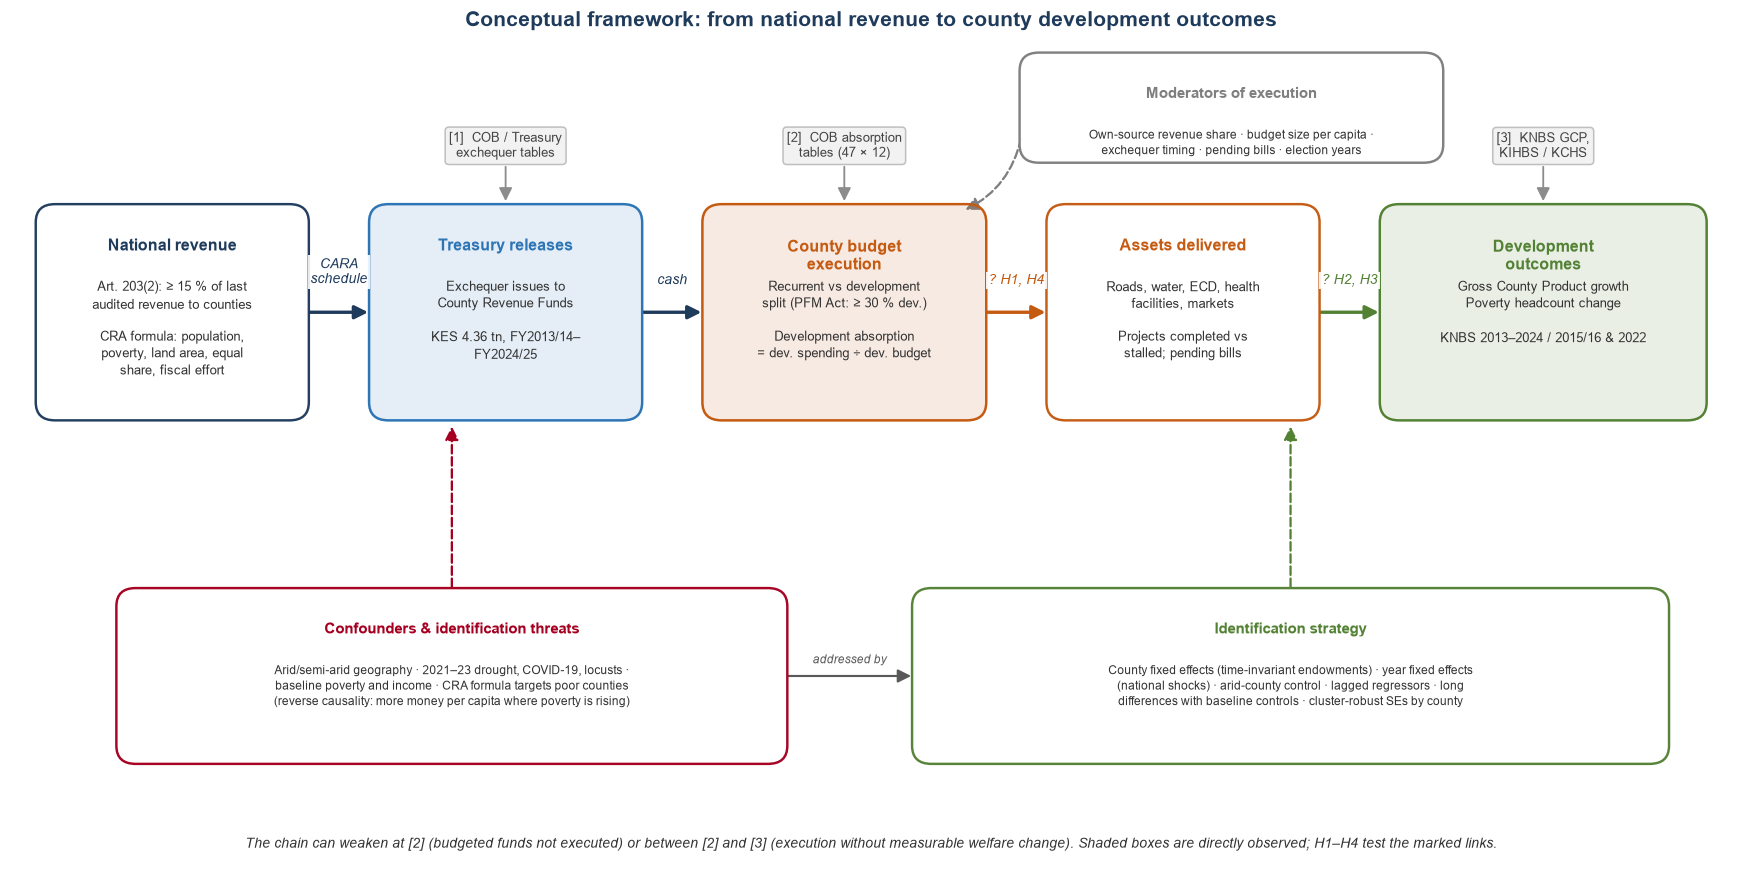

In [2]:
fig, ax = plt.subplots(figsize=(16, 8.2)); ax.set_xlim(0, 16); ax.set_ylim(0, 8.2); ax.axis("off")

PAL = {"nat": "#1f3b5c", "flow": "#2e75b6", "exec": "#c55a11", "out": "#548235", "mod": "#7f7f7f", "conf": "#a50021"}

def box(x, y, w, h, title, body="", fc="#ffffff", ec="#1f3b5c", tc="#1f3b5c", lw=1.6, fs=10.5, bfs=8.6, shade=False):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.18",
                                fc=(ec if shade else fc), ec=ec, lw=lw, alpha=0.98 if not shade else 0.12, zorder=2))
    if shade:
        ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.18", fc="none", ec=ec, lw=lw, zorder=3))
    ax.text(x + w/2, y + h - 0.32, title, ha="center", va="top", fontsize=fs, fontweight="bold", color=tc, zorder=4)
    if body:
        ax.text(x + w/2, y + h - 0.72, body, ha="center", va="top", fontsize=bfs, color="#333333", zorder=4, linespacing=1.35)

def arrow(x1, y1, x2, y2, color="#1f3b5c", lw=2.2, style="-|>", ls="-", rad=0.0, label=None, lx=0, ly=0.18, lc=None, fs=9):
    ax.add_patch(FancyArrowPatch((x1, y1), (x2, y2), arrowstyle=style, mutation_scale=18, lw=lw, color=color, ls=ls,
                                 connectionstyle=f"arc3,rad={rad}", zorder=1))
    if label:
        ax.text((x1+x2)/2 + lx, (y1+y2)/2 + ly, label, ha="center", va="bottom", fontsize=fs, color=lc or color,
                fontstyle="italic", zorder=5, bbox=dict(fc="white", ec="none", pad=1.5, alpha=0.9))

# ---- main results chain (y ≈ 4.4-6.6) ----
Y, H = 4.5, 2.1
box(0.25, Y, 2.5, H, "National revenue", "Art. 203(2): ≥ 15 % of last\naudited revenue to counties\n\nCRA formula: population,\npoverty, land area, equal\nshare, fiscal effort", ec=PAL["nat"])
box(3.35, Y, 2.5, H, "Treasury releases", "Exchequer issues to\nCounty Revenue Funds\n\nKES 4.36 tn, FY2013/14–\nFY2024/25", ec=PAL["flow"], tc=PAL["flow"], shade=True)
box(6.45, Y, 2.6, H, "County budget\nexecution", "Recurrent vs development\nsplit (PFM Act: ≥ 30 % dev.)\n\nDevelopment absorption\n= dev. spending ÷ dev. budget", ec=PAL["exec"], tc=PAL["exec"], shade=True)
box(9.65, Y, 2.5, H, "Assets delivered", "Roads, water, ECD, health\nfacilities, markets\n\nProjects completed vs\nstalled; pending bills", ec=PAL["exec"], tc=PAL["exec"])
box(12.75, Y, 3.0, H, "Development\noutcomes", "Gross County Product growth\nPoverty headcount change\n\nKNBS 2013–2024 / 2015/16 & 2022", ec=PAL["out"], tc=PAL["out"], shade=True)

arrow(2.75, Y+H/2, 3.35, Y+H/2, label="CARA\nschedule", ly=0.25)
arrow(5.85, Y+H/2, 6.45, Y+H/2, label="cash", ly=0.25)
arrow(9.05, Y+H/2, 9.65, Y+H/2, color=PAL["exec"], label="? H1, H4", ly=0.25)
arrow(12.15, Y+H/2, 12.75, Y+H/2, color=PAL["out"], label="? H2, H3", ly=0.25)

# ---- measurement points ----
for x, t in [(4.6, "[1]  COB / Treasury\nexchequer tables"), (7.75, "[2]  COB absorption\ntables (47 × 12)"), (14.25, "[3]  KNBS GCP,\nKIHBS / KCHS")]:
    ax.text(x, Y+H+0.45, t, ha="center", va="bottom", fontsize=8.3, color="#444444",
            bbox=dict(boxstyle="round,pad=0.3", fc="#f2f2f2", ec="#bfbfbf"))
    arrow(x, Y+H+0.42, x, Y+H+0.02, color="#8c8c8c", lw=1.2, style="-|>")

# ---- moderators of execution (top-right) ----
box(9.4, 7.05, 3.9, 1.05, "Moderators of execution", "Own-source revenue share · budget size per capita ·\nexchequer timing · pending bills · election years", ec=PAL["mod"], tc=PAL["mod"], fs=9.5, bfs=8)
arrow(9.4, 7.3, 8.85, Y+H-0.05, color=PAL["mod"], lw=1.5, ls="--", style="-|>", rad=-0.25)

# ---- confounders (bottom) ----
box(1.0, 1.1, 6.2, 1.7, "Confounders & identification threats", "Arid/semi-arid geography · 2021–23 drought, COVID-19, locusts ·\nbaseline poverty and income · CRA formula targets poor counties\n(reverse causality: more money per capita where poverty is rising)", ec=PAL["conf"], tc=PAL["conf"], fs=9.5, bfs=8)
box(8.4, 1.1, 7.0, 1.7, "Identification strategy", "County fixed effects (time-invariant endowments) · year fixed effects\n(national shocks) · arid-county control · lagged regressors · long\ndifferences with baseline controls · cluster-robust SEs by county", ec=PAL["out"], tc=PAL["out"], fs=9.5, bfs=8)
for x in (4.1, 11.9):
    arrow(x, 2.8, x, Y-0.05, color=PAL["conf"] if x < 8 else PAL["out"], lw=1.5, ls="--", style="-|>")
arrow(7.2, 1.95, 8.4, 1.95, color="#595959", lw=1.4, style="-|>", label="addressed by", ly=0.1, fs=8)

ax.text(8, 0.25, "The chain can weaken at [2] (budgeted funds not executed) or between [2] and [3] (execution without measurable welfare change). "
                 "Shaded boxes are directly observed; H1–H4 test the marked links.", ha="center", fontsize=9, color="#333333", fontstyle="italic")
ax.set_title("Conceptual framework: from national revenue to county development outcomes", fontsize=14, fontweight="bold", color=PAL["nat"], pad=12)
savefig("fig0_conceptual_framework")

### 6. Data loading and cleaning

The COB county tables were machine-extracted from the original COB PDFs — the FY2019/20–FY2024/25 reports from cob.go.ke and the FY2013/14–FY2018/19 reports from Wayback Machine archives of the same site. For 2019/20 onward the development budget, development expenditure, absorption-rate and recurrent-expenditure columns were validated by the extraction routine (the 47-county sum reproduces each report's own national total). Earlier reports have no consolidated all-county table, so county figures were parsed from narrative paragraphs; these are subjected to an internal-consistency check below. The equitable-share, exchequer-release and own-source-revenue columns came from per-county "Revenue Performance" tables with inconsistent layouts, so implausibly small values (< KES 100 million for transfers) are treated as parse errors and set to missing rather than used.

In [3]:
# ---- County fiscal panel (COB) ----
fp = pd.read_csv(DATA / "county_fiscal_panel.csv", na_values=["NA"])
num_cols = [c for c in fp.columns if c.endswith("_kes") or c.endswith("_pct")]
for c in num_cols:
    fp[c] = pd.to_numeric(fp[c], errors="coerce")

# parse-error filter on transfer columns (a county receives billions, never < 100m)
for c in ["equitable_share_allocation_kes", "total_exchequer_disbursed_kes"]:
    fp.loc[fp[c] < 1e8, c] = np.nan
fp.loc[fp["own_source_revenue_kes"] < 1e7, "own_source_revenue_kes"] = np.nan   # smallest counties still collect > KES 10m

# Internal-consistency validation. FY2019/20+ rows come from the consolidated all-county COB table (sum-checked
# against the national total). FY2013/14-2018/19 rows were regex-extracted from per-county narrative paragraphs and
# contain unit slips (million/billion); a row is 'validated' only if expenditure/budget reproduces the reported
# absorption rate within 3 pp. Unvalidated early rows keep the reported absorption rate but lose the KES amounts.
computed = 100 * fp["development_expenditure_kes"] / fp["development_budget_kes"]
early = fp["fiscal_year"] < "2019/20"
fp["validated"] = (~early) | (((computed - fp["development_absorption_rate_pct"]).abs() <= 3)
                               & fp["development_absorption_rate_pct"].between(0, 110))
bad = early & ~fp["validated"]
fp.loc[bad, ["development_budget_kes", "development_expenditure_kes", "recurrent_expenditure_kes"]] = np.nan
fp.loc[early & ~fp["development_absorption_rate_pct"].between(0, 110), "development_absorption_rate_pct"] = np.nan

fp["year"] = fp["fiscal_year"].map(fy_end)
fp["dev_absorb"] = fp["development_absorption_rate_pct"]
fp = fp.sort_values(["county", "year"]).reset_index(drop=True)

# NDMA classification of the 23 arid and semi-arid (ASAL) counties; the 8 arid "frontier" counties receive the
# largest per-capita transfers and were hardest hit by the 2021-23 drought, so this is an important control.
ARID = ["Turkana", "Marsabit", "Mandera", "Wajir", "Garissa", "Isiolo", "Samburu", "Tana River"]
SEMI_ARID = ["Baringo", "West Pokot", "Laikipia", "Kajiado", "Narok", "Kitui", "Makueni", "Embu", "Tharaka-Nithi",
             "Meru", "Kilifi", "Kwale", "Lamu", "Taita/Taveta", "Nyeri"]
fp["arid"] = fp["county"].isin(ARID).astype(int)
fp["asal"] = fp["county"].isin(ARID + SEMI_ARID).astype(int)

# ---- National aggregates ----
nat = pd.read_csv(DATA / "national_fiscal_aggregates.csv", na_values=["NA"])
for c in nat.columns[1:]:
    if c != "source_quality":
        nat[c] = pd.to_numeric(nat[c], errors="coerce")
nat["year"] = nat["fiscal_year"].map(fy_end)

# ---- KNBS outcomes ----
gcp = pd.read_csv(DATA / "county_gcp.csv")[["county", "year", "gcp_nominal_kes_mn", "gcp_real_kes_mn", "gcp_per_capita_kes"]]
pop = pd.read_csv(DATA / "county_population.csv")[["county", "census_year", "population"]]
pov = pd.read_csv(DATA / "county_poverty.csv")[["county", "survey_year", "poverty_headcount_pct"]]

# ---- Projects (COB FY2022/23 flagship development projects with completion status) ----
proj = pd.read_csv(DATA / "county_projects.csv", na_values=["NA"])

# ---- county name harmonisation ----
def norm(s):
    return (s.str.strip().str.replace("’", "'", regex=False)
             .str.replace(r"\s+County$", "", regex=True)
             .str.replace("Elgeyo Marakwet", "Elgeyo/Marakwet").str.replace("Elgeyo-Marakwet", "Elgeyo/Marakwet")
             .str.replace("Taita Taveta", "Taita/Taveta").str.replace("Taita-Taveta", "Taita/Taveta")
             .str.replace("Tharaka Nithi", "Tharaka-Nithi").str.replace("^Tharaka$", "Tharaka-Nithi", regex=True)
             .str.replace("Nairobi$", "Nairobi City", regex=True)
             .str.replace("Homabay", "Homa Bay").str.replace("Transnzoia", "Trans Nzoia"))
for d in [fp, gcp, pop, pov, proj]:
    d["county"] = norm(d["county"])

counties = sorted(fp["county"].unique())
missing = [set(counties) ^ set(d["county"].unique()) for d in [gcp, pop, pov]]
print("Counties in fiscal panel:", len(counties), "| name mismatches vs GCP/pop/pov:", missing)
print("Fiscal panel:", fp.shape, "| fiscal years:", fp["fiscal_year"].min(), "to", fp["fiscal_year"].max())

Counties in fiscal panel: 47 | name mismatches vs GCP/pop/pov: [set(), set(), set()]
Fiscal panel: (564, 16) | fiscal years: 2013/14 to 2024/25


In [4]:
# ---- Population: interpolate 2009-2019 and extrapolate with the inter-censal growth rate ----
pw = pop.pivot(index="county", columns="census_year", values="population")
g = (pw[2019] / pw[2009]) ** (1/10) - 1
years = range(2013, 2026)
pop_long = pd.DataFrame({
    "county": np.repeat(pw.index, len(years)),
    "year": np.tile(list(years), len(pw)),
})
pop_long["population"] = [pw.loc[c, 2019] * (1 + g[c]) ** (y - 2019) for c, y in zip(pop_long["county"], pop_long["year"])]

# ---- GCP growth ----
gcp = gcp.sort_values(["county", "year"])
gcp["ln_real_gcp"] = np.log(gcp["gcp_real_kes_mn"])
gcp["g_real"] = gcp.groupby("county")["ln_real_gcp"].diff() * 100           # % growth, log points
gcp["g_nominal"] = gcp.groupby("county")["gcp_nominal_kes_mn"].transform(lambda s: np.log(s).diff()*100)

# ---- Merge analysis panel ----
panel = (fp.merge(pop_long, on=["county", "year"], how="left")
           .merge(gcp, on=["county", "year"], how="left"))
panel["dev_exp_pc"] = panel["development_expenditure_kes"] / panel["population"]
panel["dev_budget_pc"] = panel["development_budget_kes"] / panel["population"]
panel["ln_dev_exp_pc"] = np.log(panel["dev_exp_pc"])
panel["ln_eqshare_pc"] = np.log(panel["equitable_share_allocation_kes"] / panel["population"])
panel["osr_share"] = panel["own_source_revenue_kes"] / (panel["own_source_revenue_kes"] + panel["equitable_share_allocation_kes"])

# lags within county
panel = panel.sort_values(["county", "year"])
for v in ["dev_absorb", "ln_dev_exp_pc"]:
    panel[f"{v}_lag"] = panel.groupby("county")[v].shift(1)
# lead growth (growth in year after the FY closes)
panel["g_real_lead"] = panel.groupby("county")["g_real"].shift(-1)

cov = (panel.groupby("fiscal_year")[["dev_absorb", "development_expenditure_kes", "equitable_share_allocation_kes",
                                      "total_exchequer_disbursed_kes", "own_source_revenue_kes", "g_real"]]
            .apply(lambda d: d.notna().sum()))
cov.columns = ["absorption", "dev_exp (validated)", "eq_share", "disbursed", "OSR", "GCP growth"]
print("Non-missing county observations by fiscal year (max 47):")
display(cov)

Non-missing county observations by fiscal year (max 47):


,absorption,dev_exp (validated),eq_share,disbursed,OSR,GCP growth
fiscal_year,,,,,,
2013/14,39,14,27,0,0,47
2014/15,39,23,0,0,0,47
2015/16,41,22,34,0,0,47
2016/17,46,27,32,0,0,47
2017/18,47,40,40,0,0,47
2018/19,45,30,41,0,0,47
2019/20,47,47,34,34,34,47
2020/21,47,47,25,26,43,47
2021/22,47,47,44,43,39,47


#### 6.1 Exploring the panel with pandas indexing and filtering

Before modelling, a quick tour of the merged panel using the main pandas selection idioms — positional `.iloc`, label-based `.loc`, boolean masks, `.query()`, `.isin()` / `.between()`, `.nlargest()`, and `pd.IndexSlice` on a MultiIndex. Each example answers a substantive question about the data.

In [5]:
# (1) .iloc — positional: first 5 rows, selected columns by position
print("(1) .iloc[:5, [0,1,6,11]] – first five rows, four columns by position")
display(panel.iloc[:5, [0, 1, 6, 11]])

# (2) .iloc with negative/step indexing — every other year for the last county in the frame
last_county = panel.iloc[-1, 0]
print(f"(2) .iloc on a county slice – every second year for {last_county}")
display(panel.loc[panel.county == last_county].iloc[::2, :][["fiscal_year", "dev_absorb", "development_expenditure_kes"]])

# (3) .loc with a boolean mask – which county-years absorbed < 30 % of the development budget?
mask = (panel["dev_absorb"] < 30) & panel["validated"]
print(f"(3) Boolean mask – {mask.sum()} county-years with development absorption below 30%")
display(panel.loc[mask, ["county", "fiscal_year", "dev_absorb", "development_budget_kes", "development_expenditure_kes"]]
             .sort_values("dev_absorb").head(10))

# (4) .query() – readable multi-condition filtering, referencing a Python variable with @
thresh = 75
print(f"(4) .query() – arid counties that absorbed ≥ {thresh}% in FY2022/23 or later")
display(panel.query("arid == 1 and dev_absorb >= @thresh and year >= 2023")[["county", "fiscal_year", "dev_absorb", "g_real"]])

# (5) .isin() + .between() – the 'big five' urban counties during the COVID years
big5 = ["Nairobi City", "Mombasa", "Kisumu", "Nakuru", "Kiambu"]
print("(5) .isin() + .between() – big urban counties, FY2019/20–2021/22")
display(panel[panel.county.isin(big5) & panel.year.between(2020, 2022)]
            .pivot(index="county", columns="fiscal_year", values="dev_absorb").round(1))

# (6) .nlargest()/.nsmallest() – the ten biggest absolute amounts of unspent development budget in a single year
panel["dev_unspent_kes_bn"] = (panel["development_budget_kes"] - panel["development_expenditure_kes"]) / 1e9
print("(6) .nlargest() – ten largest single-year unspent development budgets (KES bn)")
display(panel.nlargest(10, "dev_unspent_kes_bn")[["county", "fiscal_year", "dev_unspent_kes_bn", "dev_absorb"]])

# (7) MultiIndex + pd.IndexSlice – slice a (county, year) index by label ranges on both levels
idx = pd.IndexSlice
mi = panel.set_index(["county", "year"]).sort_index()
print("(7) pd.IndexSlice – Turkana and Wajir, 2021–2023, two columns")
display(mi.loc[idx[["Turkana", "Wajir"], 2021:2023], ["dev_absorb", "gcp_per_capita_kes"]])

# (8) Chained filter → groupby → filter again: counties that were below 50 % absorption in at least 3 of the 6 complete years
low = (panel.query("year >= 2020").assign(below50=lambda d: d.dev_absorb < 50)
            .groupby("county")["below50"].sum().loc[lambda s: s >= 3].sort_values(ascending=False))
print(f"(8) groupby + .loc[callable] – {len(low)} counties below 50% development absorption in ≥ 3 of 6 years:")
print(", ".join(f"{c} ({int(n)})" for c, n in low.items()))

(1) .iloc[:5, [0,1,6,11]] – first five rows, four columns by position


,county,fiscal_year,development_absorption_rate_pct,validated
0,Baringo,2013/14,30.70,True
1,Baringo,2014/15,59.50,False
2,Baringo,2015/16,53.90,True
3,Baringo,2016/17,56.20,True
4,Baringo,2017/18,36.40,True


(2) .iloc on a county slice – every second year for West Pokot


,fiscal_year,dev_absorb,development_expenditure_kes
552,2013/14,60.00,"984,000,000.00"
554,2015/16,NaN,NaN
556,2017/18,57.20,"983,310,000.00"
558,2019/20,54.40,"1,103,210,000.00"
560,2021/22,63.30,"1,596,710,000.00"
562,2023/24,67.30,"1,543,620,000.00"


(3) Boolean mask – 24 county-years with development absorption below 30%


,county,fiscal_year,dev_absorb,development_budget_kes,development_expenditure_kes
324,Mombasa,2013/14,2.40,"4,700,000,000.00","112,000,000.00"
468,Tana River,2013/14,3.00,"1,200,000,000.00","32,000,000.00"
192,Kisumu,2013/14,4.00,"2,500,000,000.00","98,900,000.00"
460,Taita/Taveta,2017/18,12.70,"1,630,000,000.00","206,450,000.00"
189,Kisii,2022/23,13.90,"3,303,760,000.00","457,820,000.00"
532,Vihiga,2017/18,17.50,"1,700,000,000.00","297,470,000.00"
365,Nakuru,2018/19,18.40,"8,000,000,000.00","1,480,000,000.00"
384,Narok,2013/14,22.00,"2,100,000,000.00","457,600,000.00"
544,Wajir,2017/18,22.90,"3,670,000,000.00","842,500,000.00"
196,Kisumu,2017/18,23.70,"2,840,000,000.00","669,360,000.00"


... (5 outputs left out)

,county,fiscal_year,dev_unspent_kes_bn,dev_absorb
359,Nairobi City,2024/25,10.17,29.00
356,Nairobi City,2021/22,7.31,29.30
366,Nakuru,2019/20,6.87,37.40
365,Nakuru,2018/19,6.52,18.40
352,Nairobi City,2017/18,6.19,26.10
354,Nairobi City,2019/20,6.10,24.50
332,Mombasa,2021/22,5.91,37.00
371,Nakuru,2024/25,5.37,42.00
369,Nakuru,2022/23,5.33,36.10
370,Nakuru,2023/24,5.23,46.00


(7) pd.IndexSlice – Turkana and Wajir, 2021–2023, two columns


dev_absorb  gcp_per_capita_kes
county  year                                
Turkana 2021       51.80          115,183.00
        2022       39.50          133,665.00
        2023       56.40          152,276.00
Wajir   2021       74.60           71,581.00
        2022       56.40           76,810.00
        2023       76.50           79,972.00

(8) groupby + .loc[callable] – 14 counties below 50% development absorption in ≥ 3 of 6 years:
Nairobi City (5), Nakuru (5), Laikipia (4), Kisumu (4), Busia (4), Kisii (4), Machakos (4), Garissa (3), Elgeyo/Marakwet (3), Baringo (3), Kiambu (3), Kwale (3), Taita/Taveta (3), Uasin Gishu (3)


#### 6.2 Chunked processing

The merged panel is small (564 rows), but the techniques below are the ones that scale to files that do not fit in memory — the COB PDFs behind this dataset were themselves parsed page-chunk by page-chunk. Each example is checked against the in-memory result so the chunked version is verifiably equivalent.

1. **Streaming aggregation** with `pd.read_csv(..., chunksize=)` — fold each chunk into a running total instead of loading the file.
2. **Column/dtype pruning** with `usecols=` and `dtype=` (categoricals) to shrink memory before any computation.
3. **Batch-wise estimation** with `itertools.batched` / `np.array_split` — fit one small model per county in batches, collecting results as you go.
4. **Chunked summary figure** — the sorted county array is split into four performance quartiles and each chunk is summarised by its mean path and interquartile band, instead of drawing 47 individual lines.

In [6]:
from itertools import batched          # Python ≥ 3.12
import time

# ---- (1) Streaming aggregation: national development expenditure by FY, 100 rows at a time ----
t0 = time.perf_counter()
running = {}
n_chunks = 0
for chunk in pd.read_csv(DATA / "county_fiscal_panel.csv", na_values=["NA"], chunksize=100,
                         usecols=["county", "fiscal_year", "development_expenditure_kes", "development_budget_kes", "development_absorption_rate_pct"]):
    n_chunks += 1
    # apply the same validation rule as the full load, chunk by chunk
    comp = 100 * chunk["development_expenditure_kes"] / chunk["development_budget_kes"]
    early_c = chunk["fiscal_year"] < "2019/20"
    ok = (~early_c) | (((comp - chunk["development_absorption_rate_pct"]).abs() <= 3) & chunk["development_absorption_rate_pct"].between(0, 110))
    part = chunk.loc[ok].groupby("fiscal_year")["development_expenditure_kes"].sum()
    for fy, v in part.items():
        running[fy] = running.get(fy, 0.0) + v
streamed = pd.Series(running).sort_index() / 1e9
full = panel.groupby("fiscal_year")["development_expenditure_kes"].sum() / 1e9
assert np.allclose(streamed.values, full.values), "chunked and full-load totals differ!"
print(f"(1) {n_chunks} chunks streamed in {1000*(time.perf_counter()-t0):.1f} ms; chunked == full-load totals ✔")
display(pd.DataFrame({"streamed_kes_bn": streamed, "full_load_kes_bn": full}).round(2).T)

# ---- (2) usecols + dtype pruning ----
raw_full = pd.read_csv(DATA / "county_gcp.csv")
lean = pd.read_csv(DATA / "county_gcp.csv", usecols=["county", "year", "gcp_real_kes_mn"],
                   dtype={"county": "category", "year": "int16", "gcp_real_kes_mn": "float32"})
mb = lambda d: d.memory_usage(deep=True).sum() / 1024
print(f"(2) county_gcp.csv: full load {mb(raw_full):.0f} KB → usecols+dtype {mb(lean):.0f} KB "
      f"({100*(1-mb(lean)/mb(raw_full)):.0f}% smaller); dtypes: {dict(lean.dtypes.astype(str))}")

(1) 6 chunks streamed in 14.4 ms; chunked == full-load totals ✔


,2013/14,2014/15,2015/16,2016/17,2017/18,2018/19,2019/20,2020/21,2021/22,2022/23,2023/24,2024/25
streamed_kes_bn,8.00,44.76,49.54,65.32,56.64,69.29,104.51,116.07,98.47,97.98,109.23,123.76
full_load_kes_bn,8.00,44.76,49.54,65.32,56.64,69.29,104.51,116.07,98.47,97.98,109.23,123.76


(2) county_gcp.csv: full load 126 KB → usecols+dtype 5 KB (96% smaller); dtypes: {'county': 'category', 'year': 'int16', 'gcp_real_kes_mn': 'float32'}


In [7]:
# ---- (3) Batch-wise estimation: per-county linear trend in development absorption, 12 counties per batch ----
def county_trend(d):
    d = d.dropna(subset=["dev_absorb"])
    if len(d) < 4:
        return pd.Series({"slope_pp_per_yr": np.nan, "p": np.nan, "n": len(d), "mean": d["dev_absorb"].mean()})
    m = sm.OLS(d["dev_absorb"], sm.add_constant(d["year"] - 2014)).fit()
    return pd.Series({"slope_pp_per_yr": m.params.iloc[1], "p": m.pvalues.iloc[1], "n": len(d), "mean": d["dev_absorb"].mean()})

results_batches = []
for b, batch in enumerate(batched(counties, 12), start=1):
    sub_b = panel[panel.county.isin(batch)]
    out = sub_b.groupby("county").apply(county_trend, include_groups=False)
    out["batch"] = b
    results_batches.append(out)
    print(f"   batch {b}: {len(batch):2d} counties processed ({batch[0]} … {batch[-1]})")
trends = pd.concat(results_batches)

# equivalence check against a single ungrouped pass
assert np.allclose(trends["slope_pp_per_yr"], panel.groupby("county").apply(county_trend, include_groups=False)["slope_pp_per_yr"])
print(f"(3) {len(trends)} county trends estimated in {trends.batch.nunique()} batches ✔")
print(f"    Counties with a significant (p<.10) UPWARD trend in development absorption since 2013/14: "
      f"{', '.join(trends.query('p < .1 and slope_pp_per_yr > 0').index)}")
print(f"    Significant DOWNWARD trend: {', '.join(trends.query('p < .1 and slope_pp_per_yr < 0').index) or 'none'}")
print(f"    Median trend across counties: {trends.slope_pp_per_yr.median():+.2f} pp per year")
display(pd.concat([trends.nlargest(5, "slope_pp_per_yr"), trends.nsmallest(5, "slope_pp_per_yr")]).round(2))

# np.array_split is the NumPy analogue when you need (near-)equal-sized chunks of an array/index
chunks = np.array_split(np.array(counties), 4)
print(f"    np.array_split → chunk sizes {[len(c) for c in chunks]}")

   batch 1: 12 counties processed (Baringo … Kericho)


   batch 2: 12 counties processed (Kiambu … Mandera)
   batch 3: 12 counties processed (Marsabit … Nyeri)


   batch 4: 11 counties processed (Samburu … West Pokot)


(3) 47 county trends estimated in 4 batches ✔
    Counties with a significant (p<.10) UPWARD trend in development absorption since 2013/14: Makueni, Mandera, Meru, Nakuru
    Significant DOWNWARD trend: Bomet, Isiolo, Kisii
    Median trend across counties: +0.40 pp per year


,slope_pp_per_yr,p,n,mean,batch
county,,,,,
Mandera,3.41,0.04,10.00,72.52,2
Meru,3.10,0.04,12.00,59.85,3
Nakuru,2.62,0.02,10.00,35.70,3
Makueni,2.41,0.06,10.00,60.72,2
Embu,2.07,0.19,11.00,52.95,1
Kisii,-4.56,0.00,11.00,51.75,2
Bomet,-3.20,0.02,12.00,72.68,1
Isiolo,-3.07,0.01,11.00,66.97,1
Kiambu,-2.07,0.12,12.00,57.21,2


    np.array_split → chunk sizes [12, 12, 12, 11]


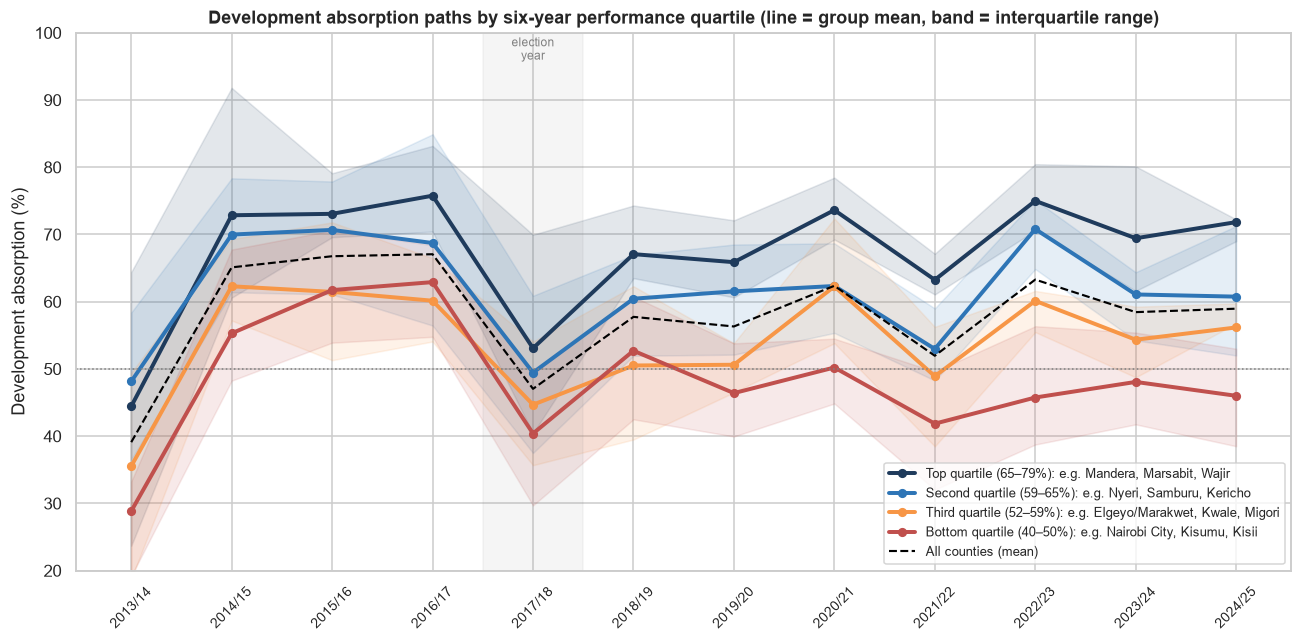

Group means by period (%):


,Top quartile,Second quartile,Third quartile,Bottom quartile
period,,,,
FY13/14–18/19,64.50,61.50,52.40,50.00
FY19/20–24/25,69.80,61.60,55.40,46.40


In [8]:
# ---- (4) Chunked summary figure: absorption paths of four performance quartiles ----
# Sort counties by their mean absorption over the six complete years and np.array_split the sorted array into
# quartiles; then summarise each chunk with its mean path and interquartile band instead of drawing 47 lines.
rank = panel.query("year >= 2020").groupby("county")["dev_absorb"].mean().sort_values(ascending=False)
quartiles = np.array_split(rank.index.to_numpy(), 4)
q_names = ["Top quartile", "Second quartile", "Third quartile", "Bottom quartile"]
q_colors = ["#1f3b5c", "#2e75b6", "#f79646", "#c0504d"]

fig, ax = plt.subplots(figsize=(12, 6))
for k, (chunk, qn, col) in enumerate(zip(quartiles, q_names, q_colors)):
    g = panel[panel.county.isin(chunk)].groupby("year")["dev_absorb"]
    m, q1, q3 = g.mean(), g.quantile(.25), g.quantile(.75)
    ax.fill_between(m.index, q1, q3, color=col, alpha=0.12)
    examples = chunk[:3] if k < 2 else chunk[-3:][::-1]      # name the extreme members of each group
    ax.plot(m.index, m.values, color=col, lw=2.6, marker="o", ms=5,
            label=f"{qn} ({rank[chunk].min():.0f}–{rank[chunk].max():.0f}%): e.g. {', '.join(examples)}")
nat_mean = panel.groupby("year")["dev_absorb"].mean()
ax.plot(nat_mean.index, nat_mean.values, color="black", lw=1.4, ls="--", label="All counties (mean)")
ax.axhline(50, ls=":", c="grey", lw=1)
ax.axvspan(2017.5, 2018.5, color="grey", alpha=0.08); ax.text(2018, 96, "election\nyear", ha="center", fontsize=8, color="grey")
ax.set_ylim(20, 100); ax.set_ylabel("Development absorption (%)"); ax.set_xlabel("")
ax.set_xticks(range(2014, 2026)); ax.set_xticklabels([f"{y-1}/{str(y)[-2:]}" for y in range(2014, 2026)], rotation=45, fontsize=9)
ax.set_title("Development absorption paths by six-year performance quartile (line = group mean, band = interquartile range)", fontsize=11.5, fontweight="bold")
ax.legend(fontsize=8.5, loc="lower right", frameon=True)
savefig("fig7_absorption_paths_by_quartile")
print("Group means by period (%):")
display(pd.DataFrame({qn: panel[panel.county.isin(ch)].assign(period=lambda d: np.where(d.year < 2020, "FY13/14–18/19", "FY19/20–24/25"))
                      .groupby("period")["dev_absorb"].mean() for ch, qn in zip(quartiles, q_names)}).round(1))

**Interpretation.** Summarising each performance quartile by its mean path brings out two patterns. First, all four groups move together over time — the 2017/18 election-year trough and the 2021/22 dip appear in every line — which indicates that common national factors account for a large share of year-to-year variation and motivates the year fixed effects used below. Second, the groups did not converge: the top quartile's mean absorption rose from 64.5 % in the first six years of devolution to 69.8 % in the second, while the bottom quartile's fell from 50.0 % to 46.4 %, widening the gap from about 15 to 23 percentage points. The bottom quartile consists largely of the more urbanised counties (Nairobi City, Nakuru, Kiambu, Kisumu, Machakos); the top quartile of the arid north and a group of mid-sized western and central counties. The interquartile bands overlap between adjacent groups in most years, consistent with the limited year-to-year persistence documented in §8.

### 7. Flow of funds since inception

Kenya's counties are financed primarily by the equitable share of nationally raised revenue, which rose from KES 190 bn in FY2013/14 to KES 418 bn in FY2024/25. The figure below shows the aggregate picture from the twelve COB annual reports since the inception of county governments: how much counties received, how much they spent on development versus recurrent items, and how the development absorption rate compares with the recurrent rate.

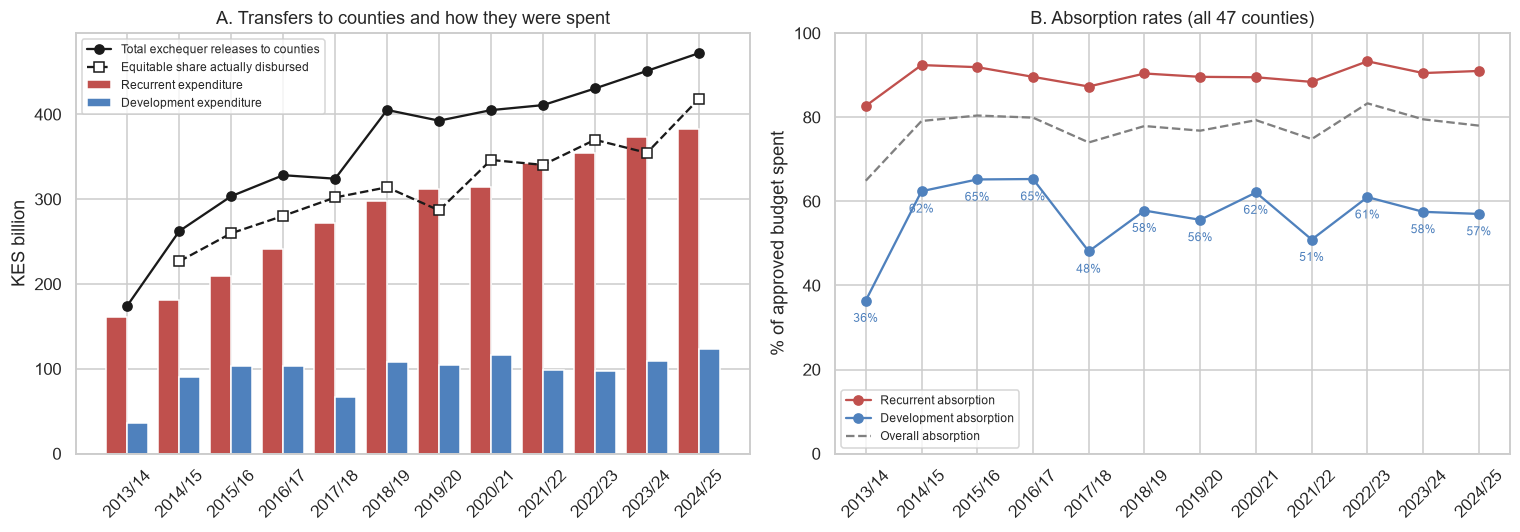

,total_exchequer_disbursed_kes_bn,total_expenditure_kes_bn,development_expenditure_total_kes_bn,recurrent_expenditure_total_kes_bn,development_absorption_rate_pct,recurrent_absorption_rate_pct,pending_bills_total_kes_bn,dev_share_of_spending_pct
fiscal_year,,,,,,,,
2013/14,174.40,169.40,36.60,160.60,36.40,82.70,NaN,21.60
2014/15,262.30,258.00,90.40,181.40,62.40,92.40,37.60,35.10
2015/16,303.50,295.30,103.40,208.80,65.20,91.90,37.40,35.00
2016/17,328.20,319.10,103.30,240.90,65.30,89.60,35.80,32.40
2017/18,324.10,303.80,66.90,271.30,48.10,87.30,108.40,22.00
2018/19,405.20,376.40,107.40,297.70,57.80,90.40,34.50,28.50
2019/20,392.50,383.80,104.50,311.60,55.60,89.60,113.80,27.20
2020/21,405.00,398.00,116.10,314.90,62.10,89.50,96.00,29.20
2021/22,410.90,401.00,98.50,342.20,50.90,88.40,153.00,24.60


Over 2013/14–2024/25: KES 4,360 bn released; KES 1,158 bn (27% of spending) went to development; KES 867 bn of approved development budgets went unspent.


In [9]:
nat_plot = nat.dropna(subset=["development_expenditure_total_kes_bn"]).copy()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ax = axes[0]
w = 0.4; x = np.arange(len(nat_plot))
ax.bar(x - w/2, nat_plot["recurrent_expenditure_total_kes_bn"], w, label="Recurrent expenditure", color="#c0504d")
ax.bar(x + w/2, nat_plot["development_expenditure_total_kes_bn"], w, label="Development expenditure", color="#4f81bd")
ax.plot(x, nat_plot["total_exchequer_disbursed_kes_bn"], "k-o", label="Total exchequer releases to counties")
ax.plot(x, nat_plot["equitable_share_total_kes_bn"], "k--s", mfc="white", label="Equitable share actually disbursed")
ax.set_xticks(x); ax.set_xticklabels(nat_plot["fiscal_year"], rotation=45)
ax.set_ylabel("KES billion"); ax.set_title("A. Transfers to counties and how they were spent"); ax.legend(fontsize=8)

ax = axes[1]
ax.plot(x, nat_plot["recurrent_absorption_rate_pct"], "-o", color="#c0504d", label="Recurrent absorption")
ax.plot(x, nat_plot["development_absorption_rate_pct"], "-o", color="#4f81bd", label="Development absorption")
ax.plot(x, nat_plot["overall_absorption_rate_pct"], "--", color="grey", label="Overall absorption")
ax.set_ylim(0, 100); ax.set_xticks(x); ax.set_xticklabels(nat_plot["fiscal_year"], rotation=45)
ax.set_ylabel("% of approved budget spent"); ax.set_title("B. Absorption rates (all 47 counties)"); ax.legend(fontsize=8)
for xi, v in zip(x, nat_plot["development_absorption_rate_pct"]):
    ax.annotate(f"{v:.0f}%", (xi, v), textcoords="offset points", xytext=(0, -14), ha="center", fontsize=8, color="#4f81bd")
savefig("fig1_national_flows_absorption")

summary = nat_plot[["fiscal_year", "total_exchequer_disbursed_kes_bn", "total_expenditure_kes_bn",
                    "development_expenditure_total_kes_bn", "recurrent_expenditure_total_kes_bn",
                    "development_absorption_rate_pct", "recurrent_absorption_rate_pct", "pending_bills_total_kes_bn"]].copy()
summary["dev_share_of_spending_pct"] = 100 * summary["development_expenditure_total_kes_bn"] / summary["total_expenditure_kes_bn"]
display(summary.set_index("fiscal_year").round(1))
tot_disb = summary["total_exchequer_disbursed_kes_bn"].sum(); tot_dev = summary["development_expenditure_total_kes_bn"].sum()
unspent = (nat_plot["development_budget_total_kes_bn"] - nat_plot["development_expenditure_total_kes_bn"]).sum()
print(f"Over {summary.fiscal_year.iloc[0]}–{summary.fiscal_year.iloc[-1]}: KES {tot_disb:,.0f} bn released; "
      f"KES {tot_dev:,.0f} bn ({100*tot_dev/summary.total_expenditure_kes_bn.sum():.0f}% of spending) went to development; "
      f"KES {unspent:,.0f} bn of approved development budgets went unspent.")

**Interpretation.** Three features stand out. First, transfers have grown in every year except FY2017/18 and FY2019/20, and exchequer releases exceeded total county spending in all twelve years, so counties have not been liquidity-constrained in aggregate. Second, the development share of spending peaked at 35 % in the second and third years of devolution and has since declined to 22–26 %; recurrent spending (wages, operations) rose from KES 161 bn to KES 383 bn, while development spending changed little in nominal terms (KES 90 bn in FY2014/15, KES 124 bn in FY2024/25) and declined in real terms. Third, the development absorption rate (panel B) shows no sustained trend: after the start-up year it rose to 62–65 %, fell to 48 % in the 2017 election year, and has since fluctuated around 57 %. Recurrent absorption has remained at 83–93 % throughout. Panel B corresponds to H1: the gap between the two series has not narrowed over the period.

### 8. Development absorption across counties (H1)

The national rate hides enormous heterogeneity. Below: the distribution of county development absorption in every year since inception (early years use the validated narrative extractions, so fewer than 47 counties appear), the ranking of counties on their average over the six years with complete data, and the persistence of absorption from one year to the next. If absorption were driven by one-off shocks (late exchequer releases, court cases, an election year) we would expect little persistence; if it reflects institutional capacity, the same counties should sit at the top and bottom year after year.

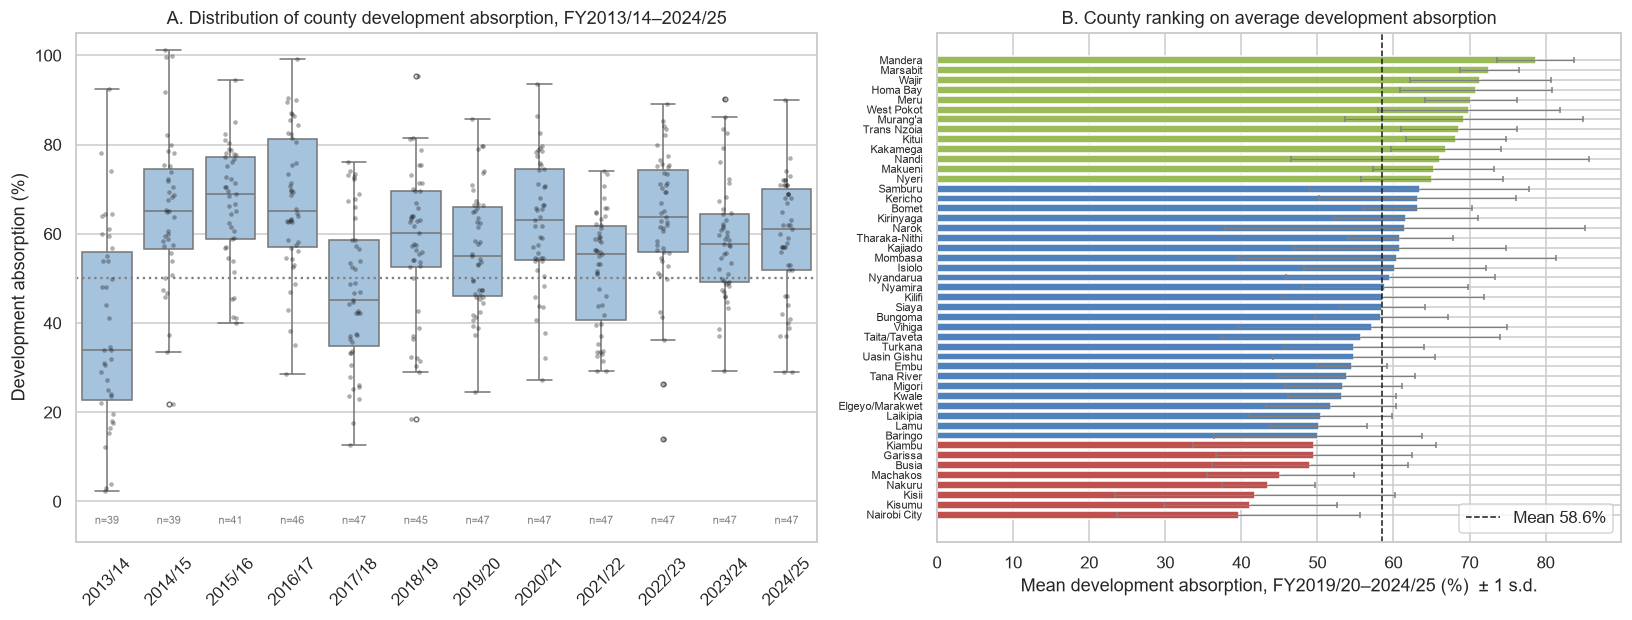

Top 8 counties:


,mean,std,min,max,count
county,,,,,
Mandera,78.70,5.00,72.00,85.30,6
Marsabit,72.60,3.90,68.30,79.00,6
Wajir,71.40,9.30,56.40,83.40,6
Homa Bay,70.90,10.00,61.70,86.30,6
Meru,70.20,6.00,62.30,79.30,6
West Pokot,69.90,12.00,54.40,89.00,6
Murang'a,69.30,15.60,41.70,85.70,6
Trans Nzoia,68.60,7.60,59.80,78.80,6


Bottom 8 counties:


,mean,std,min,max,count
county,,,,,
Nairobi City,39.60,15.90,24.50,66.40,6
Kisumu,41.20,11.30,29.00,58.20,6
Kisii,41.80,18.40,13.90,63.20,6
Nakuru,43.60,6.10,36.10,51.60,6
Machakos,45.20,9.60,32.60,58.60,6
Busia,49.00,12.90,33.80,69.00,6
Garissa,49.50,12.90,29.30,67.00,6
Kiambu,49.60,16.00,26.40,71.00,6


In [10]:
sub_all = panel.dropna(subset=["dev_absorb"])
sub = sub_all[sub_all.fiscal_year >= "2019/20"]          # complete 47-county years, used for the ranking

fig, axes = plt.subplots(1, 2, figsize=(15, 5.8), gridspec_kw={"width_ratios": [1.3, 1.2]})
ax = axes[0]
sns.boxplot(data=sub_all, x="fiscal_year", y="dev_absorb", ax=ax, color="#9dc3e6", fliersize=3)
sns.stripplot(data=sub_all, x="fiscal_year", y="dev_absorb", ax=ax, color="k", alpha=0.35, size=3)
ax.axhline(50, ls=":", c="grey"); ax.set_ylabel("Development absorption (%)"); ax.set_xlabel(""); ax.set_ylim(-9, 105)
for i, (fy, d) in enumerate(sub_all.groupby("fiscal_year")):
    ax.annotate(f"n={len(d)}", (i, -5), ha="center", fontsize=7, color="grey")
ax.set_title("A. Distribution of county development absorption, FY2013/14–2024/25"); ax.tick_params(axis="x", rotation=45)

ax = axes[1]
avg = (sub.groupby("county")["dev_absorb"].agg(["mean", "std", "min", "max", "count"]).sort_values("mean"))
colors = ["#c0504d" if v < 50 else ("#9bbb59" if v >= 65 else "#4f81bd") for v in avg["mean"]]
ax.barh(avg.index, avg["mean"], xerr=avg["std"], color=colors, ecolor="grey", capsize=2, error_kw={"lw": 0.8})
ax.axvline(sub["dev_absorb"].mean(), ls="--", c="k", lw=1, label=f"Mean {sub.dev_absorb.mean():.1f}%")
ax.set_xlabel("Mean development absorption, FY2019/20–2024/25 (%)  ± 1 s.d."); ax.tick_params(axis="y", labelsize=7)
ax.set_title("B. County ranking on average development absorption"); ax.legend(loc="lower right")
savefig("fig2_county_absorption_distribution")

print("Top 8 counties:"); display(avg.tail(8)[::-1].round(1))
print("Bottom 8 counties:"); display(avg.head(8).round(1))

Spearman rank correlation of county absorption between consecutive years:


,ρ
2019/20→2020/21,0.32
2020/21→2021/22,0.16
2021/22→2022/23,0.49
2022/23→2023/24,0.47
2023/24→2024/25,0.56



AR(1): absorb_t = 43.5 + 0.27·absorb_(t-1)   (cluster-robust SE 0.05, p=0.000, R²=0.08)
Share of absorption variance that is BETWEEN counties: 40% ; within-county (year-to-year): 60%


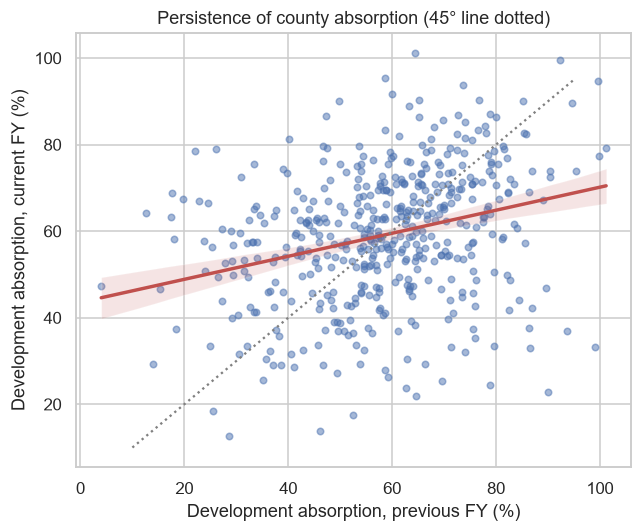

In [11]:
# ---- Persistence: year-on-year rank correlation and AR(1) ----
wide = sub.pivot(index="county", columns="fiscal_year", values="dev_absorb")
fys = list(wide.columns)
rank_corr = pd.Series({f"{fys[i]}→{fys[i+1]}": wide[fys[i]].corr(wide[fys[i+1]], method="spearman") for i in range(len(fys)-1)})
print("Spearman rank correlation of county absorption between consecutive years:")
display(rank_corr.round(2).to_frame("ρ"))

ar = smf.ols("dev_absorb ~ dev_absorb_lag", data=panel.dropna(subset=["dev_absorb", "dev_absorb_lag"])).fit(cov_type="cluster", cov_kwds={"groups": panel.dropna(subset=["dev_absorb", "dev_absorb_lag"])["county"]})
print(f"\nAR(1): absorb_t = {ar.params['Intercept']:.1f} + {ar.params['dev_absorb_lag']:.2f}·absorb_(t-1)   "
      f"(cluster-robust SE {ar.bse['dev_absorb_lag']:.2f}, p={ar.pvalues['dev_absorb_lag']:.3f}, R²={ar.rsquared:.2f})")

# share of variance between vs within counties
tot_var = sub["dev_absorb"].var()
between = sub.groupby("county")["dev_absorb"].transform("mean").var()
print(f"Share of absorption variance that is BETWEEN counties: {100*between/tot_var:.0f}% ; within-county (year-to-year): {100*(1-between/tot_var):.0f}%")

fig, ax = plt.subplots(figsize=(6, 5))
sns.regplot(data=panel, x="dev_absorb_lag", y="dev_absorb", ax=ax, scatter_kws={"alpha": .5, "s": 18}, line_kws={"color": "#c0504d"})
ax.plot([10, 95], [10, 95], ls=":", c="grey"); ax.set_xlabel("Development absorption, previous FY (%)"); ax.set_ylabel("Development absorption, current FY (%)")
ax.set_title("Persistence of county absorption (45° line dotted)")
savefig("fig3_absorption_persistence")

**Interpretation.** Over the six complete years (Figure 2B), the highest average development absorption was recorded by Mandera (79 %), Marsabit (73 %), Wajir (71 %) and Homa Bay (71 %), and the lowest by Nairobi City (40 %), Kisumu (41 %), Kisii (42 %) and Nakuru (44 %). The eight arid counties have a mean of 63 % against 58 % for the other 39. The persistence statistics qualify the ranking: the Spearman rank correlation between consecutive years ranges from 0.16 to 0.56, the AR(1) coefficient is 0.27, and 60 % of the total variation in absorption is within-county (year-to-year) rather than between counties. A county's position in the ranking in one year is therefore only weakly informative about its position in the next, and the standard-deviation bars in Figure 2B are wide relative to the differences between county means. The implications of this volatility for the outcome regressions are examined in Sections 9–10.

#### 8.1 What explains absorption?

Two mechanical explanations compete with the "capacity" story: (i) counties that *budget* ambitiously for development spend a lower share of it; (ii) counties that depend more on own-source revenue (which usually under-performs its target) have less cash to execute. We check both with county and year fixed effects, so the coefficients reflect within-county changes.

In [12]:
d = panel.dropna(subset=["dev_absorb", "dev_budget_pc"]).copy()
d["ln_dev_budget_pc"] = np.log(d["dev_budget_pc"])
d = d.set_index(["county", "year"])

m_a = PanelOLS.from_formula("dev_absorb ~ ln_dev_budget_pc + EntityEffects + TimeEffects", data=d).fit(cov_type="clustered", cluster_entity=True)
d2 = d.dropna(subset=["osr_share", "ln_eqshare_pc"])
m_b = PanelOLS.from_formula("dev_absorb ~ ln_dev_budget_pc + osr_share + ln_eqshare_pc + EntityEffects + TimeEffects", data=d2).fit(cov_type="clustered", cluster_entity=True)

from linearmodels.panel import compare
print(compare({"(a) budget size": m_a, "(b) + revenue mix": m_b}, stars=True, precision="std_errors"))
print("Column (a): all validated county-years FY2013/14-2024/25. Column (b): restricted to county-years with usable revenue tables (FY2019/20+).")

                     Model Comparison                    
                        (a) budget size (b) + revenue mix
---------------------------------------------------------
Dep. Variable                dev_absorb        dev_absorb
Estimator                      PanelOLS          PanelOLS
No. Observations                    438               125
Cov. Est.                     Clustered         Clustered
R-squared                        0.0187            0.1348
R-Squared (Within)              -0.0293            0.0595
R-Squared (Between)             -5.2589           -7.7803
R-Squared (Overall)             -4.9908           -7.1421
F-statistic                      7.2045            3.7386
P-value (F-stat)                 0.0076            0.0148
=====================      ============      ============
ln_dev_budget_pc              -10.756**           -8.9463
                               (5.0153)          (17.164)
osr_share                                       334.69***
              

**Interpretation.** Within a county, a 10 % larger development budget per capita is associated with a development absorption rate about 1 pp lower (column a, p < 0.05). This suggests that part of the variation in absorption reflects the size of the approved budget relative to what can be procured and paid within the fiscal year, rather than execution alone. The revenue-mix results (column b; smaller sample because the COB revenue tables could not be parsed for every county) indicate that the share of revenue a county raises itself is positively associated with execution: a 10 pp higher own-source share corresponds to roughly 33 pp higher absorption. Own-source revenue is available to the county from the start of the fiscal year, whereas the equitable share is released in tranches, so this pattern is consistent with a cash-flow mechanism, although the small sample warrants caution.

#### 8.2 The geography of money, execution and outcomes

Choropleth maps of the 47 counties (boundaries: geoBoundaries ADM1, public domain). Reading the four panels together is the visual version of the research question: does the map of *where the money is executed* (A, B) look like the map of *where development happened* (C, D)? Hatched counties are the eight arid "frontier" counties.

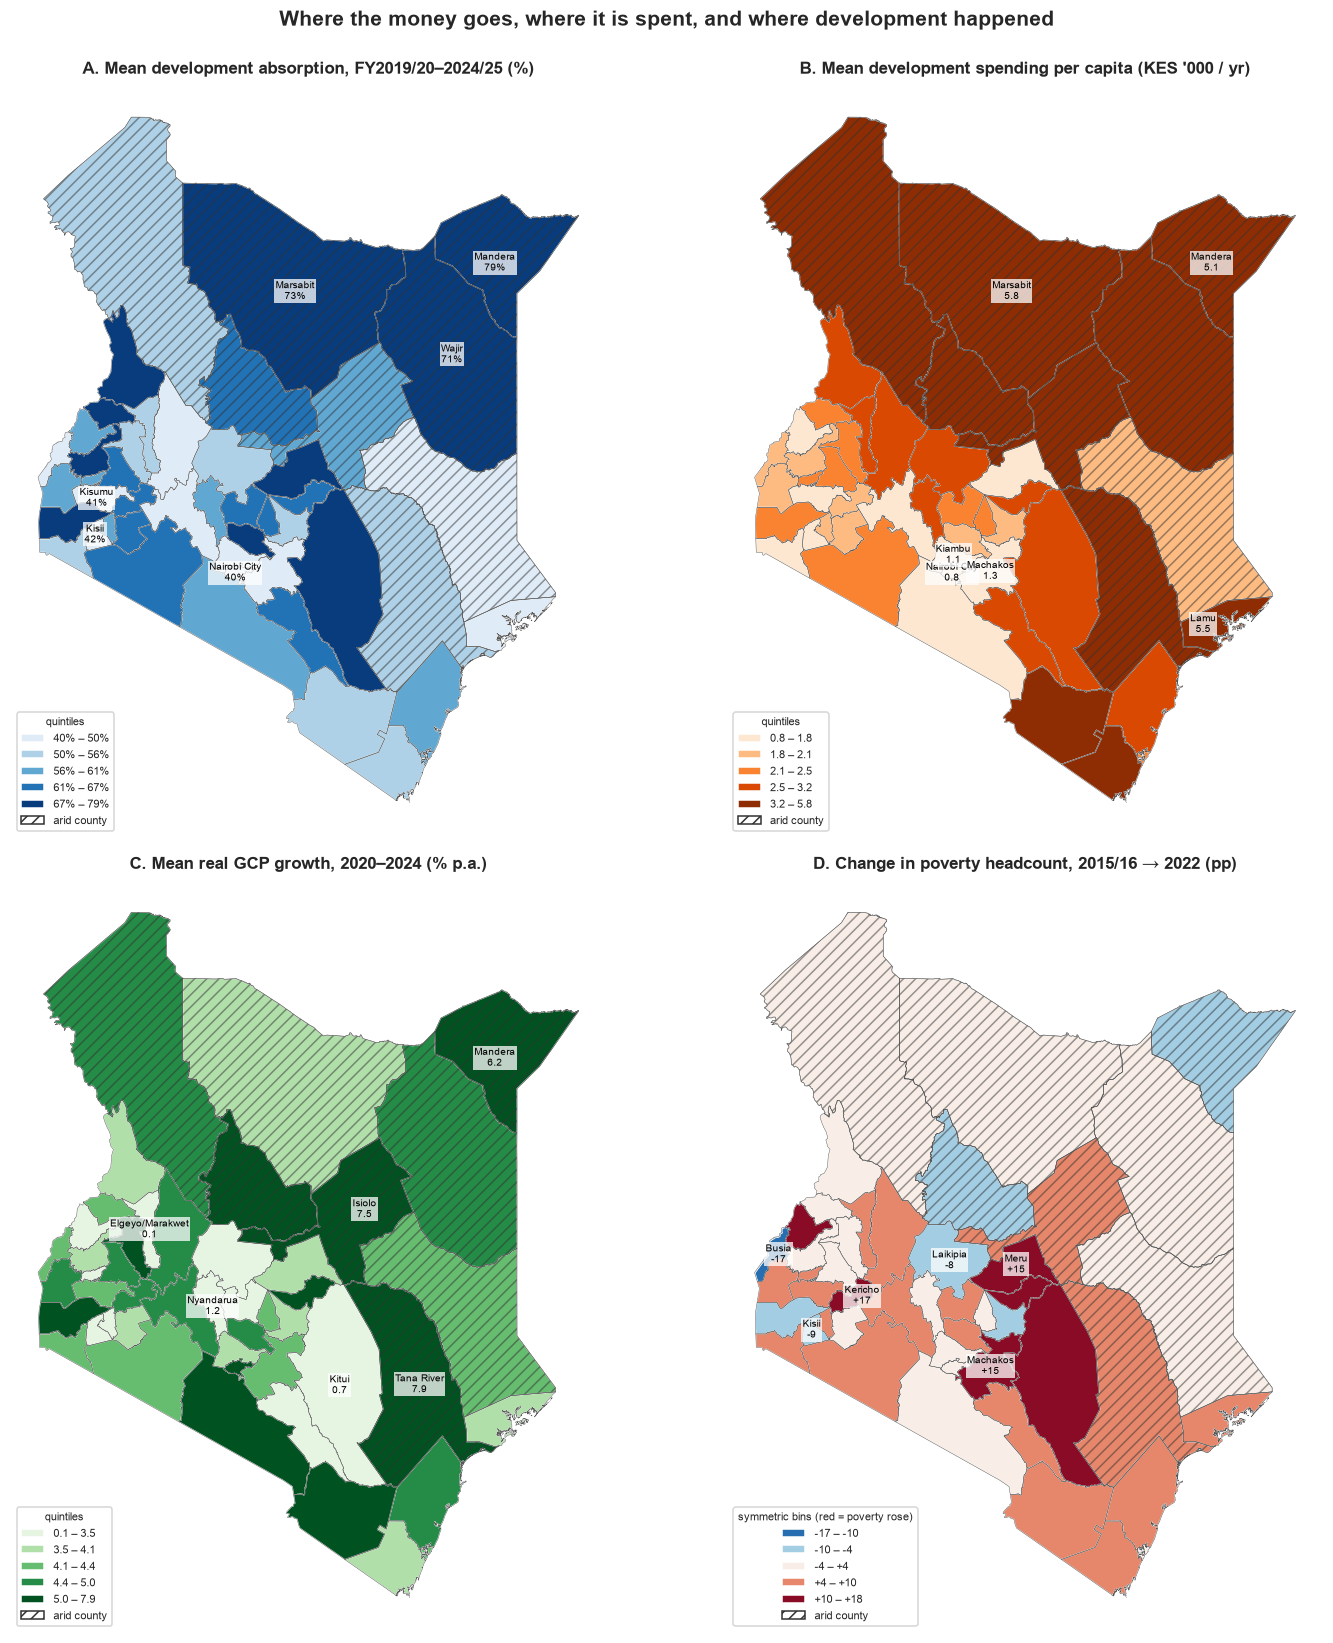

In [13]:
kenya = gpd.read_file(DATA / "kenya_counties.geojson")[["shapeName", "geometry"]].rename(columns={"shapeName": "county"})
kenya["county"] = norm(kenya["county"])
assert set(kenya.county) == set(counties), set(kenya.county) ^ set(counties)

# county-level indicators for mapping
geo = (panel.query("year >= 2020").groupby("county")
            .agg(absorb=("dev_absorb", "mean"), dev_exp_pc=("dev_exp_pc", "mean"), g_real=("g_real", "mean"), arid=("arid", "first")))
pov_w = pov.pivot(index="county", columns="survey_year", values="poverty_headcount_pct").rename(columns={"2015/16": "pov_2015", "2022": "pov_2022"})
geo = geo.join(pov_w)
geo["d_pov"] = geo["pov_2022"] - geo["pov_2015"]
geo["dev_exp_pc_k"] = geo["dev_exp_pc"] / 1e3
kmap = kenya.merge(geo, left_on="county", right_index=True, how="left")
kmap["label_pt"] = kmap.geometry.representative_point()

def choropleth(ax, col, title, cmap, legend_fmt="{:.0f}", k=5, diverging=False, note=None):
    vals = kmap[col]
    if diverging:   # symmetric bins around zero
        lim = np.nanmax(np.abs(vals)); bins = np.linspace(-lim, lim, k + 1)
        kmap["_bin"] = pd.cut(vals, bins, include_lowest=True)
    else:
        kmap["_bin"] = pd.qcut(vals, k, duplicates="drop")
    cats = kmap["_bin"].cat.categories; colors = plt.get_cmap(cmap)(np.linspace(0.12, 0.95, len(cats)))
    for cat, colr in zip(cats, colors):
        kmap[kmap["_bin"] == cat].plot(ax=ax, color=colr, edgecolor="white", linewidth=0.6)
    kmap[kmap.arid == 1].plot(ax=ax, facecolor="none", edgecolor="#333333", hatch="///", linewidth=0.4, alpha=0.5)
    kenya.boundary.plot(ax=ax, color="#555555", linewidth=0.3)
    # label extremes
    for _, r in pd.concat([kmap.nlargest(3, col), kmap.nsmallest(3, col)]).iterrows():
        ax.annotate(f"{r.county}\n{legend_fmt.format(r[col])}", (r.label_pt.x, r.label_pt.y), ha="center", va="center", fontsize=6.5,
                    color="black", bbox=dict(fc="white", ec="none", alpha=0.75, pad=0.8))
    handles = [plt.Rectangle((0, 0), 1, 1, fc=c) for c in colors]
    labels = [f"{legend_fmt.format(max(cat.left, np.nanmin(vals)))} – {legend_fmt.format(cat.right)}" for cat in cats]
    handles.append(plt.Rectangle((0, 0), 1, 1, fc="none", ec="#333333", hatch="///")); labels.append("arid county")
    ax.legend(handles, labels, loc="lower left", fontsize=7.5, title=note, title_fontsize=7.5, frameon=True)
    ax.set_title(title, fontsize=11, fontweight="bold"); ax.set_axis_off()

fig, axes = plt.subplots(2, 2, figsize=(14, 15))
choropleth(axes[0, 0], "absorb", "A. Mean development absorption, FY2019/20–2024/25 (%)", "Blues", "{:.0f}%", note="quintiles")
choropleth(axes[0, 1], "dev_exp_pc_k", "B. Mean development spending per capita (KES '000 / yr)", "Oranges", "{:.1f}", note="quintiles")
choropleth(axes[1, 0], "g_real", "C. Mean real GCP growth, 2020–2024 (% p.a.)", "Greens", "{:.1f}", note="quintiles")
choropleth(axes[1, 1], "d_pov", "D. Change in poverty headcount, 2015/16 → 2022 (pp)", "RdBu_r", "{:+.0f}", diverging=True, note="symmetric bins (red = poverty rose)")
fig.suptitle("Where the money goes, where it is spent, and where development happened", fontsize=14, fontweight="bold", y=0.995)
savefig("fig_map_absorption_outcomes")

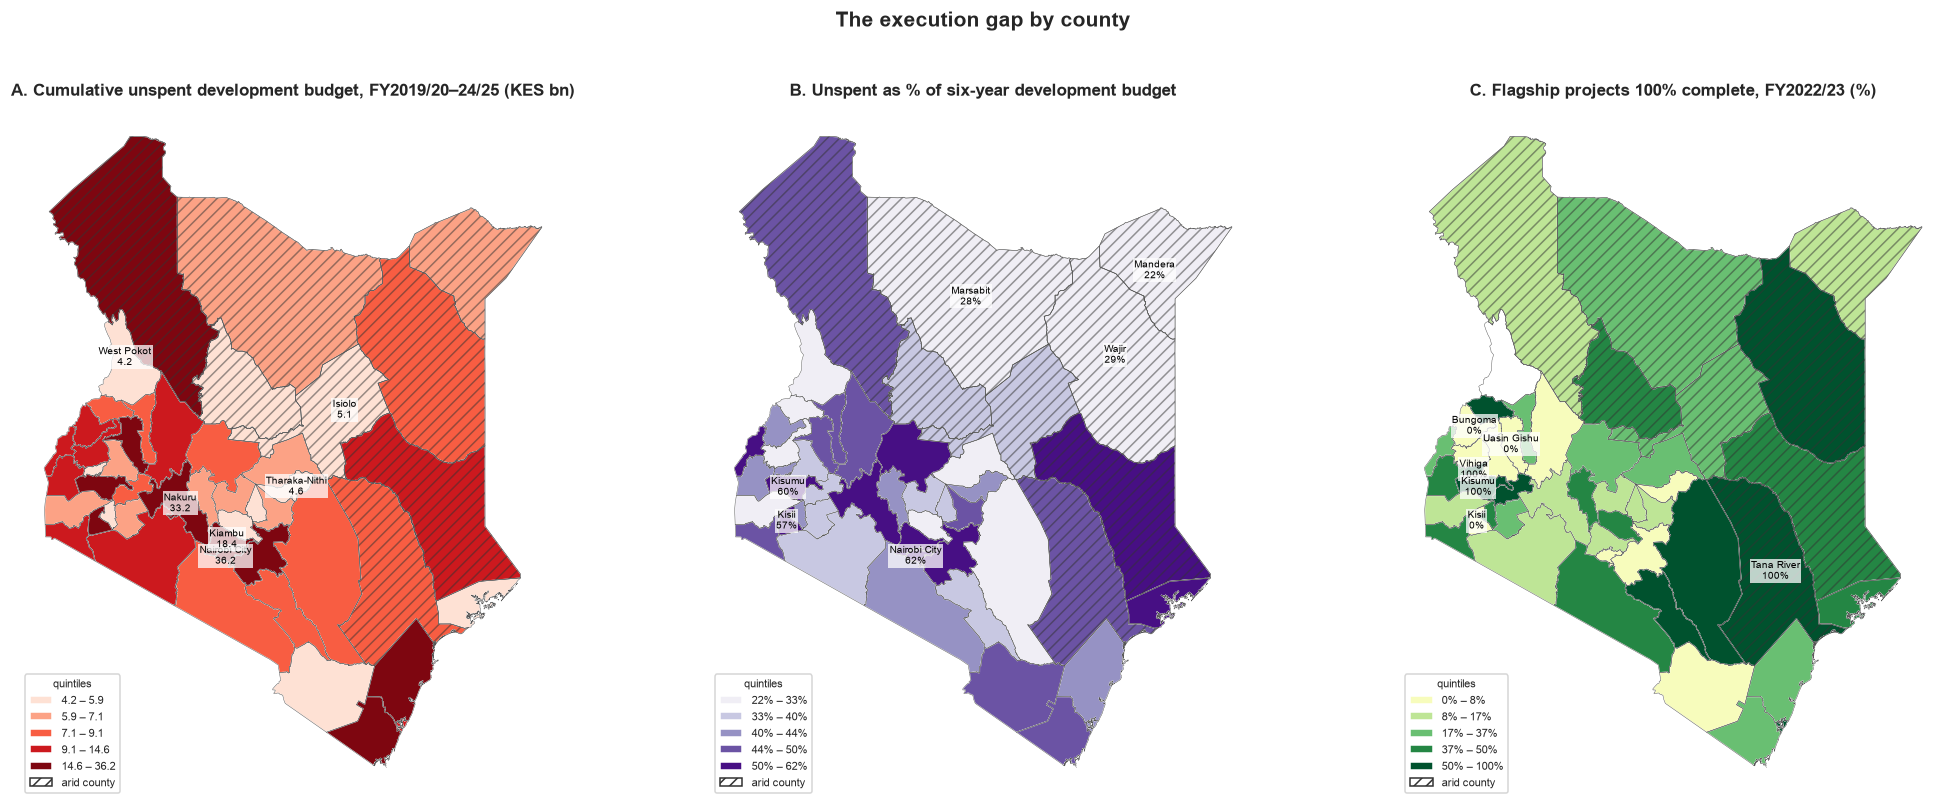

Spatial correlations across the 47 counties (Spearman ρ):


,absorb,dev_exp_pc,g_real,d_pov,unspent,completed_share
absorb,1.00,0.36,0.01,-0.01,-0.57,0.20
dev_exp_pc,0.36,1.00,0.10,0.03,-0.40,0.18
g_real,0.01,0.10,1.00,-0.14,0.05,-0.19
d_pov,-0.01,0.03,-0.14,1.00,-0.07,0.13
unspent,-0.57,-0.40,0.05,-0.07,1.00,-0.21
completed_share,0.20,0.18,-0.19,0.13,-0.21,1.00


In [14]:
# ---- Map of the two components of the execution gap: unspent development budgets and project completion ----
geo2 = panel.query("year >= 2020").groupby("county").agg(unspent=("dev_unspent_kes_bn", "sum"), dev_budget=("development_budget_kes", "sum"))
geo2["unspent_share"] = 100 * geo2["unspent"] * 1e9 / geo2["dev_budget"]
geo2 = geo2.join(proj.set_index("county")[["projects_total", "projects_completed"]])
geo2["completed_share"] = 100 * geo2["projects_completed"] / geo2["projects_total"]
kmap = kenya.merge(geo.join(geo2), left_on="county", right_index=True, how="left"); kmap["label_pt"] = kmap.geometry.representative_point()

fig, axes = plt.subplots(1, 3, figsize=(19, 7.2))
choropleth(axes[0], "unspent", "A. Cumulative unspent development budget, FY2019/20–24/25 (KES bn)", "Reds", "{:.1f}", note="quintiles")
choropleth(axes[1], "unspent_share", "B. Unspent as % of six-year development budget", "Purples", "{:.0f}%", note="quintiles")
choropleth(axes[2], "completed_share", "C. Flagship projects 100% complete, FY2022/23 (%)", "YlGn", "{:.0f}%", note="quintiles")
fig.suptitle("The execution gap by county", fontsize=14, fontweight="bold", y=1.02)
savefig("fig_map_execution_gap")

print("Spatial correlations across the 47 counties (Spearman ρ):")
display(geo.join(geo2)[["absorb", "dev_exp_pc", "g_real", "d_pov", "unspent", "completed_share"]].corr(method="spearman").round(2))

**Reading the maps.** Panels A and B of the first figure follow the national core–periphery pattern: the arid north-east (Mandera, Wajir, Marsabit) and the coast receive the most development funding per person and execute the highest share of it, while the more populous central and lake-basin counties (Nairobi City, Kiambu, Kisumu, Kisii, Nakuru) receive the least per person and execute the lowest share. Panels C (growth) and D (poverty change) do not follow the same pattern: growth was fastest in a mixed set of arid and coastal counties, and poverty increases were concentrated in the agricultural highlands (Kericho, Meru, Machakos, Bungoma) irrespective of absorption rank. The rank correlation between absorption and growth across counties is 0.01, and between absorption and poverty change −0.01. The second figure locates the execution gap: in absolute terms it is concentrated in the large urban counties (Nairobi City KES 36 bn unspent, Nakuru KES 33 bn), which account for a substantial share of the national development under-spend, while in relative terms the arid counties leave the smallest share of their budgets unspent.

### 9. Does absorption translate into development? (H2: Gross County Product)

KNBS's Gross County Product series gives real county output for 2013–2024. We relate real GCP growth in calendar year $t$ to development absorption and development spending per capita in the fiscal year ending June $t$ (and, as a robustness check, the preceding fiscal year). Pooled (year-effects-only) estimates exploit *between*-county variation — do high-absorbing counties grow faster? — while the two-way fixed-effects estimates ask whether a county grows faster *in years when it absorbs more* than its own average.

In [15]:
reg_all = panel.dropna(subset=["g_real", "dev_absorb", "ln_dev_exp_pc"]).copy()
reg_all["absorb10"] = reg_all["dev_absorb"] / 10          # effect of a 10-pp increase in absorption
reg_all["absorb10_lag"] = reg_all["dev_absorb_lag"] / 10
regi_all = reg_all.set_index(["county", "year"])          # extended panel: all validated county-years, 2014-2025
reg = reg_all[reg_all.year >= 2020]
regi = reg.set_index(["county", "year"])                  # main panel: complete 47-county data, FY2019/20-2024/25

specs = {
 "(1)": ("g_real ~ 1 + absorb10 + TimeEffects", regi, PooledOLS),
 "(2)": ("g_real ~ 1 + absorb10 + ln_dev_exp_pc + TimeEffects", regi, PooledOLS),
 "(3)": ("g_real ~ absorb10 + EntityEffects + TimeEffects", regi, PanelOLS),
 "(4)": ("g_real ~ absorb10 + ln_dev_exp_pc + EntityEffects + TimeEffects", regi, PanelOLS),
 "(5)": ("g_real ~ absorb10_lag + ln_dev_exp_pc_lag + EntityEffects + TimeEffects",
         regi.dropna(subset=["absorb10_lag", "ln_dev_exp_pc_lag"]), PanelOLS),
 "(6)": ("g_real ~ absorb10 + ln_dev_exp_pc + EntityEffects + TimeEffects", regi_all, PanelOLS),
}
spec_key = {"(1)": "Pooled OLS, year FE", "(2)": "Pooled OLS + dev. spending p.c., year FE", "(3)": "County + year FE",
            "(4)": "County + year FE + dev. spending p.c.", "(5)": "County + year FE, regressors lagged one FY",
            "(6)": "As (4), extended panel 2014–2025 (validated early rows)"}
results = {}
for name, (f, data, est) in specs.items():
    if est is PooledOLS:
        # PooledOLS has no TimeEffects keyword – add year dummies manually
        f2 = f.replace(" + TimeEffects", "") + " + C(year_d)"
        dd = data.copy(); dd["year_d"] = dd.index.get_level_values("year")
        results[name] = PooledOLS.from_formula(f2, data=dd).fit(cov_type="clustered", cluster_entity=True)
    else:
        results[name] = est.from_formula(f, data=data).fit(cov_type="clustered", cluster_entity=True)

print(compare(results, stars=True, precision="std_errors"))
print("\nModel key: " + " | ".join(f"{k} {v}" for k, v in spec_key.items()))
print("Dependent variable: real GCP growth (log points ×100). absorb10 = development absorption / 10, so the coefficient is the effect of +10 pp absorption. SEs clustered by county.")
print("Columns (1)-(5): complete 47-county panel FY2019/20-2024/25 (growth 2020-24). Column (6): adds validated county-years from FY2013/14-2018/19 (growth 2014-19).")

                                              Model Comparison                                             
                                  (1)           (2)           (3)           (4)           (5)           (6)
-----------------------------------------------------------------------------------------------------------
Dep. Variable                  g_real        g_real        g_real        g_real        g_real        g_real
Estimator                   PooledOLS     PooledOLS      PanelOLS      PanelOLS      PanelOLS      PanelOLS
No. Observations                  235           235           235           235           218           391
Cov. Est.                   Clustered     Clustered     Clustered     Clustered     Clustered     Clustered
R-squared                      0.1915        0.1959     7.805e-05        0.0032        0.0454        0.0059
R-Squared (Within)             0.2160        0.2177        0.0022       -0.0121        0.0042        0.0085
R-Squared (Between)         


                 (B1)   (B2) + arid
-----------------------------------
Intercept      13.9885* 10.8459    
               (8.4839) (9.2135)   
absorb         -0.0205  -0.0107    
               (0.0222) (0.0201)   
ln_dev_exp_pc  0.2530   -0.5247    
               (0.6392) (0.6138)   
ln_gcp_pc_2019 -0.8864  -0.1924    
               (0.5708) (0.5223)   
arid                    1.8693***  
                        (0.7024)   
R-squared      0.0856   0.2164     
R-squared Adj. 0.0218   0.1418     
N              47       47         
R²             0.09     0.22       
Standard errors in parentheses.
* p<.1, ** p<.05, ***p<.01
Dependent variable: mean real GCP growth 2020-24 (%), one observation per county, HC1 SEs.


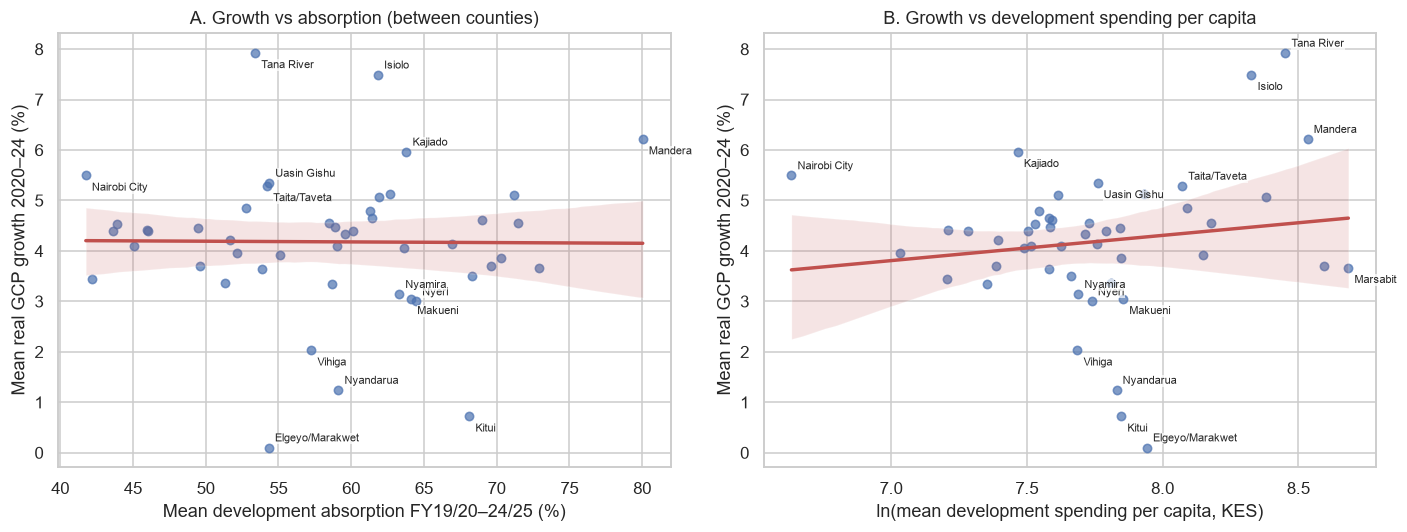

In [16]:
# ---- Between-county view: six-year average growth vs average absorption ----
bt = (panel[panel.year.between(2020, 2024)].groupby("county")
        .agg(g_real=("g_real", "mean"), absorb=("dev_absorb", "mean"), dev_exp_pc=("dev_exp_pc", "mean"),
             gcp_pc_2019=("gcp_per_capita_kes", "first"), arid=("arid", "first")).dropna())
bt["ln_dev_exp_pc"] = np.log(bt["dev_exp_pc"]); bt["ln_gcp_pc_2019"] = np.log(bt["gcp_pc_2019"])
mb1 = smf.ols("g_real ~ absorb + ln_dev_exp_pc + ln_gcp_pc_2019", data=bt).fit(cov_type="HC1")
mb2 = smf.ols("g_real ~ absorb + ln_dev_exp_pc + ln_gcp_pc_2019 + arid", data=bt).fit(cov_type="HC1")
from statsmodels.iolib.summary2 import summary_col
print(summary_col([mb1, mb2], stars=True, model_names=["(B1)", "(B2) + arid"], info_dict={"N": lambda m: f"{int(m.nobs)}", "R²": lambda m: f"{m.rsquared:.2f}"}))
print("Dependent variable: mean real GCP growth 2020-24 (%), one observation per county, HC1 SEs.")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, xv, xl in zip(axes, ["absorb", "ln_dev_exp_pc"], ["Mean development absorption FY19/20–24/25 (%)", "ln(mean development spending per capita, KES)"]):
    sns.regplot(data=bt, x=xv, y="g_real", ax=ax, scatter_kws={"s": 30, "alpha": .7}, line_kws={"color": "#c0504d"})
    lab = bt[(bt["g_real"] - bt["g_real"].mean()).abs().gt(1.0) | bt[xv].isin([bt[xv].min(), bt[xv].max()])]
    annotate_points(ax, lab, xv, "g_real")
    ax.set_xlabel(xl); ax.set_ylabel("Mean real GCP growth 2020–24 (%)")
axes[0].set_title("A. Growth vs absorption (between counties)"); axes[1].set_title("B. Growth vs development spending per capita")
savefig("fig4_growth_vs_absorption")

**Interpretation.** No specification detects an association between the absorption rate and growth. Pooled across counties (columns 1–2), a 10 pp higher absorption rate is associated with between +0.01 and −0.12 pp of growth, with standard errors several times the point estimates; within counties over time (columns 3–4, 6) the coefficient varies in sign between −0.25 and +0.57 and is not statistically significant in any case. The year effects in columns 1–2 (+4.8 pp in 2021, +4.2 pp in 2023) are an order of magnitude larger than any absorption coefficient, indicating that county growth over this period was dominated by common national shocks. The only variable with a statistically significant association is the level of development spending: lagged development spending per capita (column 5) has a coefficient of 4.2 (p < 0.01), implying that a 10 % increase in development spending per person is followed by approximately 0.4 pp faster real GCP growth in the following year. Column 6, the extended 2014–2025 panel, roughly doubles the sample and reproduces the null result for absorption. The between-county regression (B1–B2) adds a convergence pattern: with an arid-county indicator included, arid counties grew about 1.9 pp a year faster than other counties over 2020–24 (p < 0.01), while absorption and spending remain insignificant in that specification.

### 10. Poverty (H3): long difference 2015/16 → 2022

KNBS measured county poverty headcounts in the 2015/16 KIHBS and again in the 2022 Kenya Continuous Household Survey. The change between the two is regressed on the county's average development absorption and its average annual development spending per capita over the validated fiscal years from FY2013/14 to FY2021/22 (averages rather than sums, because early-year coverage differs across counties), controlling for the 2015/16 baseline (convergence). The eight arid counties are treated separately because they receive the largest per-capita transfers *and* bore the brunt of the 2021–23 drought.

Fiscal years per county entering the averages: absorption 6-9, spending 4-9



                     (1)        (2)        (3)     (4) + arid (5) non-arid only
-------------------------------------------------------------------------------
Intercept         12.8295*** -26.1835   48.1585    61.1319    55.0132          
                  (4.5245)   (19.0360)  (39.7601)  (47.8684)  (51.2744)        
absorb            -0.0623    -0.1111    -0.1780**  -0.1792**  -0.1490*         
                  (0.0901)   (0.0802)   (0.0728)   (0.0753)   (0.0854)         
pov_2015          -0.1467**  -0.2371*** -0.3318*** -0.3877*** -0.4084***       
                  (0.0647)   (0.0829)   (0.0927)   (0.1188)   (0.1242)         
ln_cum_dev_exp_pc            5.9008**   6.2606***  5.0420**   6.1977**         
                             (2.7365)   (2.4286)   (2.4632)   (2.7359)         
ln_gcp_pc_2016                          -5.9444**  -6.1126*   -6.4196**        
                                        (2.8774)   (3.1494)   (3.2269)         
arid                                   

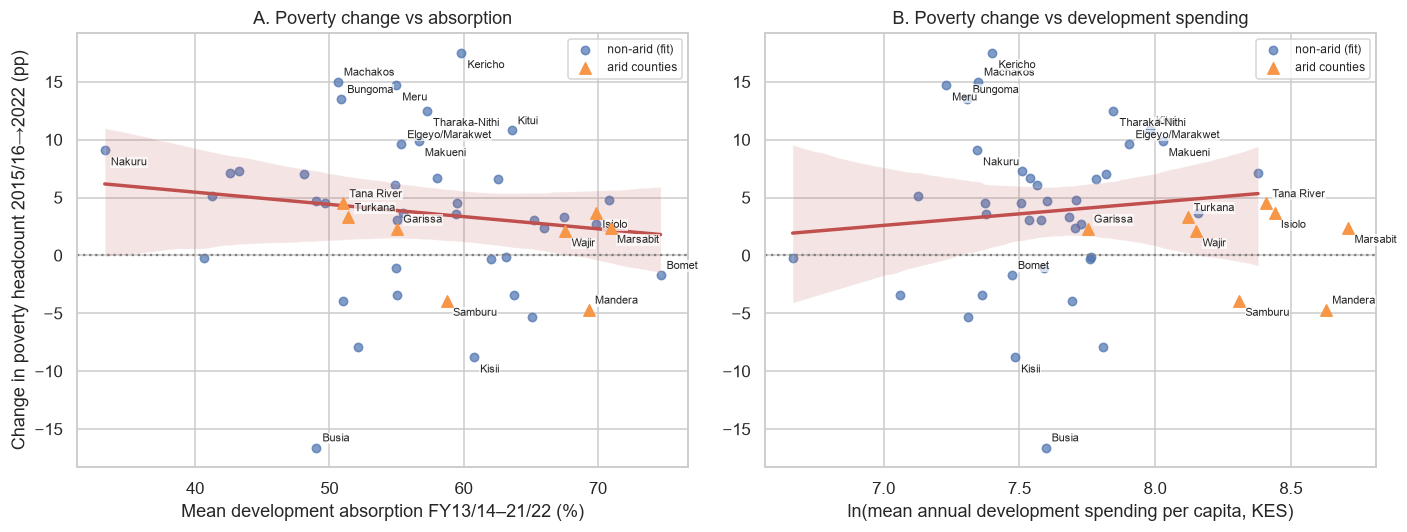

In [17]:
pw_pov = pov.pivot(index="county", columns="survey_year", values="poverty_headcount_pct")
pw_pov.columns = ["pov_2015", "pov_2022"]
pw_pov["d_pov"] = pw_pov["pov_2022"] - pw_pov["pov_2015"]

fisc_pre22 = panel[panel.year <= 2022].groupby("county").agg(
    absorb=("dev_absorb", "mean"), dev_exp_pc=("dev_exp_pc", "mean"), n_absorb=("dev_absorb", "count"),
    n_exp=("dev_exp_pc", "count"), arid=("arid", "first"), asal=("asal", "first"))
fisc_pre22["ln_cum_dev_exp_pc"] = np.log(fisc_pre22["dev_exp_pc"])     # log of mean annual development spending per capita
pv = pw_pov.join(fisc_pre22).join(gcp[gcp.year == 2016].set_index("county")["gcp_per_capita_kes"].rename("gcp_pc_2016"))
pv["ln_gcp_pc_2016"] = np.log(pv["gcp_pc_2016"])
pv = pv.dropna()
print(f"Fiscal years per county entering the averages: absorption {pv.n_absorb.min()}-{pv.n_absorb.max()}, spending {pv.n_exp.min()}-{pv.n_exp.max()}")

p1 = smf.ols("d_pov ~ absorb + pov_2015", data=pv).fit(cov_type="HC1")
p2 = smf.ols("d_pov ~ absorb + ln_cum_dev_exp_pc + pov_2015", data=pv).fit(cov_type="HC1")
p3 = smf.ols("d_pov ~ absorb + ln_cum_dev_exp_pc + pov_2015 + ln_gcp_pc_2016", data=pv).fit(cov_type="HC1")
p4 = smf.ols("d_pov ~ absorb + ln_cum_dev_exp_pc + pov_2015 + ln_gcp_pc_2016 + arid", data=pv).fit(cov_type="HC1")
p5 = smf.ols("d_pov ~ absorb + ln_cum_dev_exp_pc + pov_2015 + ln_gcp_pc_2016", data=pv[pv.arid == 0]).fit(cov_type="HC1")
from statsmodels.iolib.summary2 import summary_col
print(summary_col([p1, p2, p3, p4, p5], stars=True, model_names=["(1)", "(2)", "(3)", "(4) + arid", "(5) non-arid only"],
                  info_dict={"N": lambda m: f"{int(m.nobs)}", "R²": lambda m: f"{m.rsquared:.2f}"}))
print(f"\nNational: mean county poverty {pv.pov_2015.mean():.1f}% (2015/16) → {pv.pov_2022.mean():.1f}% (2022); "
      f"{(pv.d_pov < 0).sum()} of {len(pv)} counties reduced poverty.")
print("Arid counties: mean poverty change {:+.1f} pp; others: {:+.1f} pp".format(pv[pv.arid==1].d_pov.mean(), pv[pv.arid==0].d_pov.mean()))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, xv in zip(axes, ["absorb", "ln_cum_dev_exp_pc"]):
    sns.regplot(data=pv[pv.arid == 0], x=xv, y="d_pov", ax=ax, scatter_kws={"s": 30, "alpha": .7}, line_kws={"color": "#c0504d"}, label="non-arid (fit)")
    ax.scatter(pv[pv.arid == 1][xv], pv[pv.arid == 1]["d_pov"], marker="^", s=55, color="#f79646", label="arid counties", zorder=5)
    ax.axhline(0, c="grey", ls=":"); ax.legend(fontsize=8)
    lab = pv[(pv["d_pov"].abs() > 8) | (pv["arid"] == 1) | pv["absorb"].isin([pv.absorb.min(), pv.absorb.max()])]
    annotate_points(ax, lab, xv, "d_pov")
axes[0].set_xlabel("Mean development absorption FY13/14–21/22 (%)"); axes[1].set_xlabel("ln(mean annual development spending per capita, KES)")
axes[0].set_ylabel("Change in poverty headcount 2015/16→2022 (pp)"); axes[1].set_ylabel("")
axes[0].set_title("A. Poverty change vs absorption"); axes[1].set_title("B. Poverty change vs development spending")
savefig("fig5_poverty_change")

**Interpretation.** Poverty headcounts rose in 33 of 47 counties between 2015/16 and 2022, and the strongest predictor of the change is the baseline level: counties with higher initial poverty recorded smaller increases (columns 1–5), consistent with convergence. Conditional on this, decade-average development absorption has a modest negative association with the poverty change: in the fully specified models (columns 3–4) a county whose absorption averaged 10 pp higher over FY2013/14–2021/22 recorded a poverty increase about 1.8 pp smaller (p < 0.05); the estimate is 1.5 pp (p < 0.10) when the eight arid counties are excluded. This is the only outcome for which the absorption rate is statistically significant, and the association appears only when absorption is averaged over most of the study period — using the three most recent years alone it is insignificant. One interpretation is that execution matters through the cumulative stock of completed assets rather than through single-year performance; the data cannot distinguish this from other explanations.

The positive coefficient on development spending per capita requires careful interpretation. Conditional on baseline poverty and income, counties with higher development spending per person recorded larger poverty increases. The most plausible explanation is reverse causality through the allocation formula: the equitable share is weighted towards small, low-income, rural counties, which were also the counties most exposed to the drought, locust and food-price shocks of 2017–2022. The arid indicator (+4.2 pp, column 4) is not significant, so this pattern is not confined to the eight arid counties. The coefficient does not support a large poverty-reducing effect of county development spending at the scale observed, but given the identification problem it should not be read as evidence of a harmful effect.

### 11. Projects (H4): completion of flagship development projects

The most direct test of "money → projects" is at project level. Kenya has no consolidated public register of county projects. The COB's FY2022/23 county chapters, however, list each county's highest-expenditure development projects (8–25 per county) with an implementation-status percentage. We use the share of these flagship projects reported as 100 % complete as the outcome. Because the National Treasury's 2018 stalled-projects inventory is a non-OCR scan and COB does not label projects "stalled", the stock of **pending bills** (unpaid obligations to contractors and suppliers — the proximate cause of stalled works) is also shown as a proxy.

46 counties; 762 flagship projects listed, 230 (30%) reported 100% complete; 4 counties reported none of their flagship projects complete.


,projects_total,projects_completed,completed_share,absorb,absorb_2223
count,46.00,46.00,46.00,46.00,46.00
mean,16.60,5.00,33.10,58.30,62.70
std,4.60,3.60,29.70,9.00,14.80
min,8.00,0.00,0.00,39.60,13.90
25%,11.00,2.00,10.00,52.10,55.80
50%,19.00,4.00,25.00,58.80,63.40
75%,20.00,8.00,46.00,64.60,73.60
max,25.00,12.00,100.00,78.70,85.30



               (1) 6-yr mean absorb (2) FY22/23 absorb (3) + spending, arid
---------------------------------------------------------------------------
Intercept      8.2719               17.3230            -19.9091            
               (33.2613)            (16.9915)          (49.7719)           
absorb         0.4255                                  0.2395              
               (0.5598)                                (0.6613)            
absorb_2223                         0.2513                                 
                                    (0.2637)                               
ln_dev_exp_pc                                          5.0117              
                                                       (7.4822)            
arid                                                   4.5381              
                                                       (13.6532)           
R-squared      0.0167               0.0157             0.0304              
R-squared A

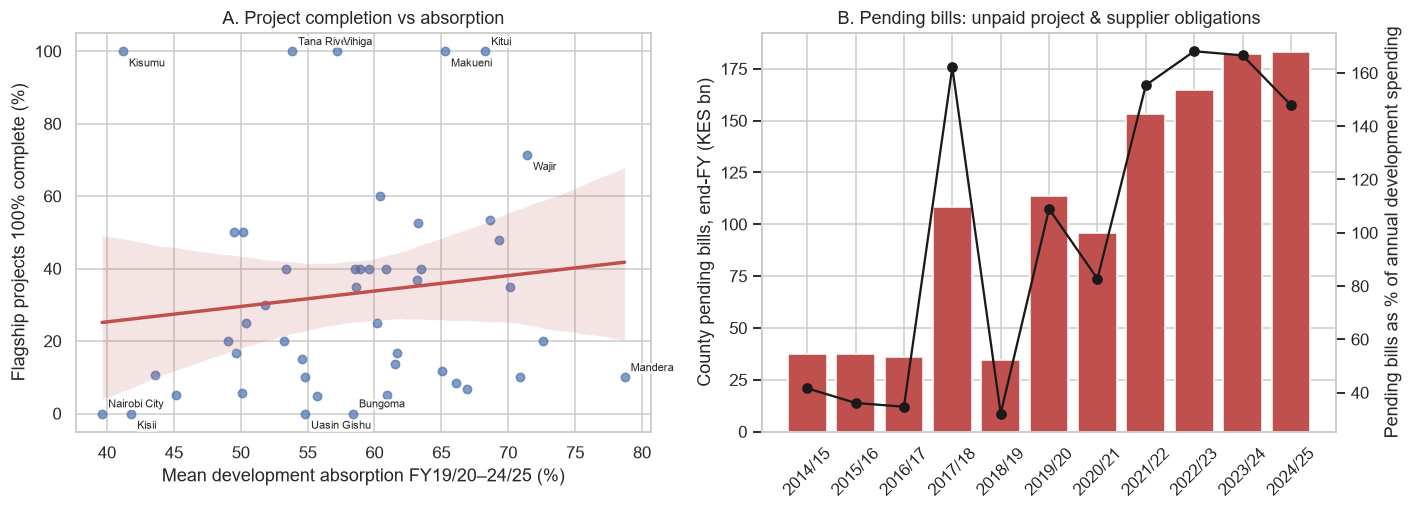

In [18]:
pj = proj.dropna(subset=["projects_total", "projects_completed"]).copy()
pj["completed_share"] = 100 * pj["projects_completed"] / pj["projects_total"]
pj = pj.merge(avg["mean"].rename("absorb"), left_on="county", right_index=True, how="inner")
pj = pj.merge(panel[panel.fiscal_year == "2022/23"][["county", "dev_absorb", "dev_exp_pc", "arid"]].rename(columns={"dev_absorb": "absorb_2223"}), on="county")
pj["ln_dev_exp_pc"] = np.log(pj["dev_exp_pc"])
print(f"{len(pj)} counties; {int(pj.projects_total.sum())} flagship projects listed, {int(pj.projects_completed.sum())} ({100*pj.projects_completed.sum()/pj.projects_total.sum():.0f}%) reported 100% complete; "
      f"{int((pj.projects_completed == 0).sum())} counties reported none of their flagship projects complete.")
display(pj[["projects_total", "projects_completed", "completed_share", "absorb", "absorb_2223"]].describe().round(1))

q1 = smf.ols("completed_share ~ absorb", data=pj).fit(cov_type="HC1")
q2 = smf.ols("completed_share ~ absorb_2223", data=pj).fit(cov_type="HC1")
q3 = smf.ols("completed_share ~ absorb + ln_dev_exp_pc + arid", data=pj).fit(cov_type="HC1")
print(summary_col([q1, q2, q3], stars=True, model_names=["(1) 6-yr mean absorb", "(2) FY22/23 absorb", "(3) + spending, arid"],
                  info_dict={"N": lambda m: f"{int(m.nobs)}", "R²": lambda m: f"{m.rsquared:.2f}"}))
print("Dependent variable: % of county's listed flagship development projects reported 100% complete, FY2022/23 (COB).")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
ax = axes[0]
sns.regplot(data=pj, x="absorb", y="completed_share", ax=ax, scatter_kws={"s": 30, "alpha": .7}, line_kws={"color": "#c0504d"})
lab = pj[(pj["completed_share"] > 70) | (pj["completed_share"] < 3) | pj["absorb"].isin([pj.absorb.min(), pj.absorb.max()])]
annotate_points(ax, lab, "absorb", "completed_share", name_col="county")
ax.set_xlabel("Mean development absorption FY19/20–24/25 (%)"); ax.set_ylabel("Flagship projects 100% complete (%)"); ax.set_title("A. Project completion vs absorption")
ax = axes[1]
pb = nat.dropna(subset=["pending_bills_total_kes_bn"])
ax.bar(pb["fiscal_year"], pb["pending_bills_total_kes_bn"], color="#c0504d")
ax2 = ax.twinx(); ax2.plot(pb["fiscal_year"], 100*pb["pending_bills_total_kes_bn"]/pb["development_expenditure_total_kes_bn"], "k-o")
ax.set_ylabel("County pending bills, end-FY (KES bn)"); ax2.set_ylabel("Pending bills as % of annual development spending"); ax2.grid(False)
ax.set_title("B. Pending bills: unpaid project & supplier obligations"); ax.tick_params(axis="x", rotation=45)
savefig("fig6_projects_pending_bills")

**Interpretation.** Of 762 flagship development projects listed by the COB for FY2022/23, 230 (30 %) were reported as 100 % complete; the median county had completed a quarter of its list, and a small number of counties none. Neither the six-year average absorption rate nor the FY2022/23 rate is associated with the completion share (R² ≈ 0.02), and adding spending per capita and the arid indicator does not change this. The pending-bills series (panel B) offers a possible explanation: unpaid obligations to contractors and suppliers stood at KES 35–38 bn a year in 2015–2017, rose to KES 108 bn in the 2017/18 election year, and have since reached KES 183 bn, approximately one and a half years of total county development spending. Expenditure used to settle prior-year obligations counts towards the absorption rate without adding to current-year project completion, which would weaken any relationship between the two measures.

### 12. Robustness

Checks on the growth regression: (i) nominal instead of real GCP growth; (ii) dropping Nairobi City (an outlier in GCP and in budget size); (iii) growth in the year *after* the fiscal year closes; (iv) excluding the COVID year 2020; (v) excluding the eight arid counties; (vi) replacing the absorption *rate* with development spending per capita alone.

In [19]:
rb = {}
def fe(f, data): return PanelOLS.from_formula(f, data=data).fit(cov_type="clustered", cluster_entity=True)
base = "absorb10 + ln_dev_exp_pc + EntityEffects + TimeEffects"
rb["(4) base"]      = fe(f"g_real ~ {base}", regi)
rb["nominal"]       = fe(f"g_nominal ~ {base}", regi.dropna(subset=["g_nominal"]))
rb["no Nairobi"]    = fe(f"g_real ~ {base}", regi.drop("Nairobi City", level="county"))
rb["lead g"]        = fe(f"g_real_lead ~ {base}", regi.dropna(subset=["g_real_lead"]))
rb["excl 2020"]     = fe(f"g_real ~ {base}", regi.drop(2020, level="year"))
rb["excl arid"]     = fe(f"g_real ~ {base}", regi[regi.arid == 0])
rb["spend only"]    = fe("g_real ~ ln_dev_exp_pc + EntityEffects + TimeEffects", regi)
rb["ext. lead g"]   = fe(f"g_real_lead ~ {base}", regi_all.dropna(subset=["g_real_lead"]))
print(compare(rb, stars=True, precision="std_errors"))
print("\nColumn key: (4) base = baseline two-way FE | nominal = nominal GCP growth | no Nairobi = Nairobi City excluded | lead g = growth in year t+1 | "
      "excl 2020 = COVID year dropped | excl arid = 8 arid counties dropped | spend only = absorption omitted | ext. lead g = lead growth, extended 2014–2025 panel")

                                                              Model Comparison                                                             
                             (4) base       nominal    no Nairobi          lead g     excl 2020     excl arid    spend only     ext. lead g
-------------------------------------------------------------------------------------------------------------------------------------------
Dep. Variable                  g_real     g_nominal        g_real     g_real_lead        g_real        g_real        g_real     g_real_lead
Estimator                    PanelOLS      PanelOLS      PanelOLS        PanelOLS      PanelOLS      PanelOLS      PanelOLS        PanelOLS
No. Observations                  235           235           230             188           188           195           235             344
Cov. Est.                   Clustered     Clustered     Clustered       Clustered     Clustered     Clustered     Clustered       Clustered
R-squared           

**Interpretation.** The null result for absorption does not depend on any single modelling choice. Across eight variants the coefficient on a 10 pp increase in absorption ranges from −0.55 to −0.02 pp of growth and is not significant in any; using nominal growth, excluding Nairobi, excluding the COVID year or excluding the arid counties leaves it essentially unchanged. Development spending per capita is positive in every column and statistically significant when growth is measured in the year *after* the fiscal year closes (+3.8 and +4.2, p < 0.10), a timing pattern consistent with a lag between capital expenditure and its use. The "spending only" column shows that the spending coefficient does not depend on the inclusion of absorption.

#### 12.1 Chunked cluster bootstrap

With only 47 clusters, asymptotic clustered standard errors can be unreliable. A **cluster (pairs) bootstrap** resamples whole counties with replacement and re-estimates the baseline two-way FE model. The replications are produced by a generator in chunks of 100, so memory stays flat no matter how many draws are requested and partial results can be inspected between chunks — the same pattern used for streaming the CSV above.

   chunk 1: 100 reps done | absorb10 mean -0.241, 95% CI [-0.821, +0.496]


   chunk 2: 200 reps done | absorb10 mean -0.241, 95% CI [-0.836, +0.443]


   chunk 3: 300 reps done | absorb10 mean -0.260, 95% CI [-0.916, +0.457]


   chunk 4: 400 reps done | absorb10 mean -0.252, 95% CI [-0.956, +0.454]
Finished 400 cluster-bootstrap replications in 31.6s


,point estimate,clustered SE,bootstrap SE,boot 2.5%,boot 97.5%,share of draws > 0
absorb10,-0.25,0.43,0.38,-0.96,0.45,0.26
ln_dev_exp_pc,1.49,1.97,1.68,-1.78,4.80,0.81


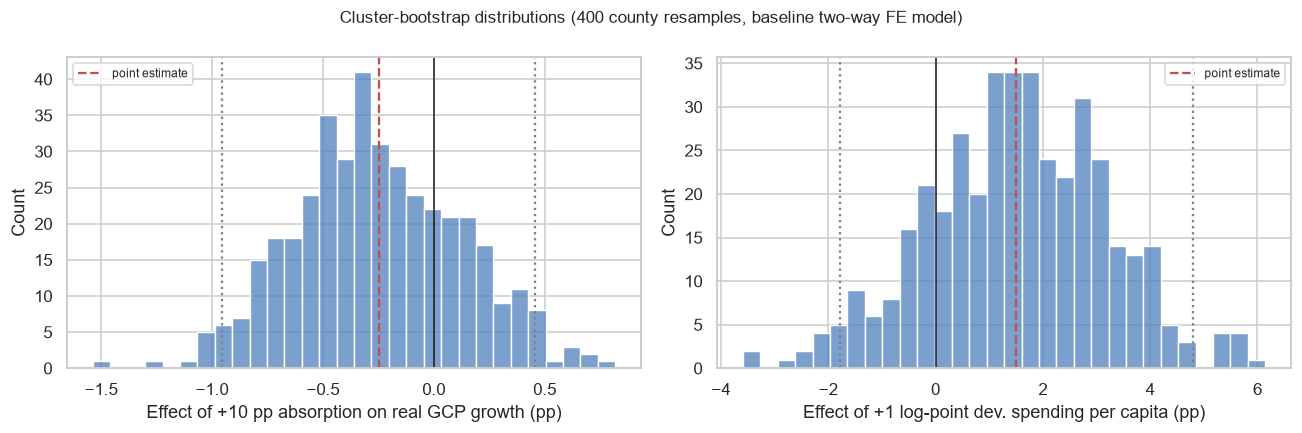

In [20]:
rng = np.random.default_rng(523)
reg_c = reg.copy()
county_list = reg_c["county"].unique()

def bootstrap_chunks(n_reps, chunk_size):
    # generator: yields a DataFrame of coefficients for each chunk of replications
    done = 0
    while done < n_reps:
        k = min(chunk_size, n_reps - done)
        rows = []
        for _ in range(k):
            draw = rng.choice(county_list, size=len(county_list), replace=True)
            # duplicate counties must become distinct entities for the fixed effects
            parts = [reg_c[reg_c.county == c].assign(county=f"{c}#{j}") for j, c in enumerate(draw)]
            bs = pd.concat(parts).set_index(["county", "year"])
            fit = PanelOLS.from_formula("g_real ~ absorb10 + ln_dev_exp_pc + EntityEffects + TimeEffects", data=bs).fit()
            rows.append(fit.params[["absorb10", "ln_dev_exp_pc"]])
        done += k
        yield pd.DataFrame(rows)

t0 = time.perf_counter(); coefs = []
for i, chunk_df in enumerate(bootstrap_chunks(n_reps=400, chunk_size=100), start=1):
    coefs.append(chunk_df)
    running_b = pd.concat(coefs)
    print(f"   chunk {i}: {len(running_b):3d} reps done | absorb10 mean {running_b.absorb10.mean():+.3f}, "
          f"95% CI [{running_b.absorb10.quantile(.025):+.3f}, {running_b.absorb10.quantile(.975):+.3f}]")
boot = pd.concat(coefs, ignore_index=True)
print(f"Finished {len(boot)} cluster-bootstrap replications in {time.perf_counter()-t0:.1f}s")

base_fit = rb["(4) base"]
summary_b = pd.DataFrame({
    "point estimate": base_fit.params[["absorb10", "ln_dev_exp_pc"]],
    "clustered SE": base_fit.std_errors[["absorb10", "ln_dev_exp_pc"]],
    "bootstrap SE": boot.std(),
    "boot 2.5%": boot.quantile(.025), "boot 97.5%": boot.quantile(.975),
    "share of draws > 0": (boot > 0).mean(),
})
display(summary_b.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, v, lab in zip(axes, ["absorb10", "ln_dev_exp_pc"], ["Effect of +10 pp absorption on real GCP growth (pp)", "Effect of +1 log-point dev. spending per capita (pp)"]):
    sns.histplot(boot[v], ax=ax, bins=30, color="#4f81bd", edgecolor="white")
    ax.axvline(0, c="k", lw=1); ax.axvline(base_fit.params[v], c="#c0504d", ls="--", label="point estimate")
    for q in (.025, .975): ax.axvline(boot[v].quantile(q), c="grey", ls=":")
    ax.set_xlabel(lab); ax.legend(fontsize=8)
fig.suptitle("Cluster-bootstrap distributions (400 county resamples, baseline two-way FE model)", fontsize=11)
savefig("fig8_cluster_bootstrap")

**Interpretation.** The bootstrap distribution for the absorption coefficient is centred near zero with a 95 % interval of approximately −1.0 to +0.5 pp of growth per 10 pp of absorption; about a quarter of resamples produce a positive estimate. The bootstrap standard error (0.38) is slightly smaller than the asymptotic clustered SE (0.43), so the analytic inference is not understating uncertainty. For development spending per capita, 81 % of resamples are positive but the interval spans zero in this contemporaneous specification; the statistically significant association reported in §9 and §12 is specific to the lagged variable. The bootstrap is therefore consistent with both results from the panel models: no detectable association between the absorption rate and growth, and a positive association between the lagged level of development spending and growth.

#### 12.2 Neural-network benchmark

The panel regressions impose linearity and additivity. A possible objection is that absorption affects growth non-linearly (for example, only above a threshold) or in interaction with other county characteristics, in which case a linear model could miss a real relationship. To test this, we fit a **multilayer perceptron (MLP)** to the same county-year data and compare its out-of-sample predictive performance with a linear model and a random forest. All models are evaluated with **county-grouped 5-fold cross-validation** (every observation of a county is held out together), so the scores measure the ability to predict growth in counties the model has not seen.

Predictors: development absorption (current and lagged), log development spending per capita (current and lagged), log GCP per capita (lagged), arid indicator, and year dummies. Target: real GCP growth. If absorption carries non-linear predictive information, the MLP and random forest should (a) beat the linear model and (b) assign absorption a high permutation importance.

In [21]:
from sklearn.neural_network import MLPRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import RidgeCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.metrics import r2_score, mean_absolute_error

nn = panel.copy()
nn["ln_gcp_pc_lag"] = nn.groupby("county")["gcp_per_capita_kes"].shift(1).pipe(np.log)
feat_num = ["dev_absorb", "dev_absorb_lag", "ln_dev_exp_pc", "ln_dev_exp_pc_lag", "ln_gcp_pc_lag", "arid"]
nn = nn.dropna(subset=feat_num + ["g_real"]).copy()
nn["year_cat"] = nn["year"].astype(str)
X, y, groups = nn[feat_num + ["year_cat"]], nn["g_real"], nn["county"]
print(f"Sample: {len(nn)} county-years, {groups.nunique()} counties, years {nn.year.min()}–{nn.year.max()}")

pre = ColumnTransformer([("num", StandardScaler(), feat_num),
                         ("yr", OneHotEncoder(handle_unknown="ignore"), ["year_cat"])])
cv = GroupKFold(n_splits=5)

# ---- Tune the MLP architecture / L2 penalty under county-grouped CV (small grid; n is only ~300) ----
grid = []
for hl in [(8,), (16,), (32, 32)]:
    for alpha in [0.1, 1.0, 10.0]:
        m = Pipeline([("pre", pre), ("m", MLPRegressor(hidden_layer_sizes=hl, alpha=alpha, max_iter=5000, early_stopping=True,
                                                       n_iter_no_change=50, random_state=523))])
        p = cross_val_predict(m, X, y, groups=groups, cv=cv)
        grid.append({"hidden layers": str(hl), "alpha (L2)": alpha, "CV R²": r2_score(y, p)})
grid = pd.DataFrame(grid).sort_values("CV R²", ascending=False)
best_hl, best_alpha = eval(grid.iloc[0]["hidden layers"]), grid.iloc[0]["alpha (L2)"]
print("MLP tuning grid (county-grouped 5-fold CV):"); display(grid.round(3).reset_index(drop=True))

models = {
    "Linear (ridge)":  Pipeline([("pre", pre), ("m", RidgeCV(alphas=np.logspace(-2, 3, 20)))]),
    "Random forest":   Pipeline([("pre", pre), ("m", RandomForestRegressor(n_estimators=500, min_samples_leaf=5, random_state=523))]),
    "MLP (tuned)":     Pipeline([("pre", pre), ("m", MLPRegressor(hidden_layer_sizes=best_hl, alpha=best_alpha, max_iter=5000,
                                                                  early_stopping=True, n_iter_no_change=50, random_state=523))]),
}
rows, preds = [], {}
for name, mdl in models.items():
    p = cross_val_predict(mdl, X, y, groups=groups, cv=cv)
    preds[name] = p
    rows.append({"model": name, "CV R²": r2_score(y, p), "CV MAE (pp)": mean_absolute_error(y, p),
                 "CV RMSE (pp)": np.sqrt(np.mean((y - p) ** 2))})
# year-mean benchmark, computed on the training folds only
naive = pd.Series(index=y.index, dtype=float)
for tr, te in cv.split(X, y, groups):
    ym = y.iloc[tr].groupby(nn["year"].iloc[tr]).mean()
    naive.iloc[te] = nn["year"].iloc[te].map(ym).values
rows.append({"model": "Year-mean only (benchmark)", "CV R²": r2_score(y, naive), "CV MAE (pp)": mean_absolute_error(y, naive),
             "CV RMSE (pp)": np.sqrt(np.mean((y - naive) ** 2))})
scores = pd.DataFrame(rows).set_index("model")
print(f"\nCounty-grouped 5-fold cross-validation (held-out counties); MLP = hidden layers {best_hl}, alpha = {best_alpha}:")
display(scores.round(3))

Sample: 300 county-years, 47 counties, years 2015–2024


MLP tuning grid (county-grouped 5-fold CV):


,hidden layers,alpha (L2),CV R²
0,"(8,)",0.10,0.79
1,"(8,)",10.00,0.78
2,"(16,)",1.00,0.75
3,"(16,)",10.00,0.74
4,"(16,)",0.10,0.74
5,"(8,)",1.00,0.74
6,"(32, 32)",10.00,0.68
7,"(32, 32)",1.00,0.67
8,"(32, 32)",0.10,0.67



County-grouped 5-fold cross-validation (held-out counties); MLP = hidden layers (8,), alpha = 0.1:


,CV R²,CV MAE (pp),CV RMSE (pp)
model,,,
Linear (ridge),0.84,3.73,6.39
Random forest,0.85,3.54,6.16
MLP (tuned),0.79,4.34,7.32
Year-mean only (benchmark),0.85,3.56,6.26


Permutation importance (increase in held-out MSE when the feature is shuffled; averaged over folds):


,Random forest,MLP (tuned)
year,453.16,315.46
ln_gcp_pc_lag,0.30,10.71
ln_dev_exp_pc_lag,0.32,10.69
ln_dev_exp_pc,-0.06,7.89
dev_absorb_lag,-1.95,7.80
arid,-0.01,1.82
dev_absorb,4.78,-1.69


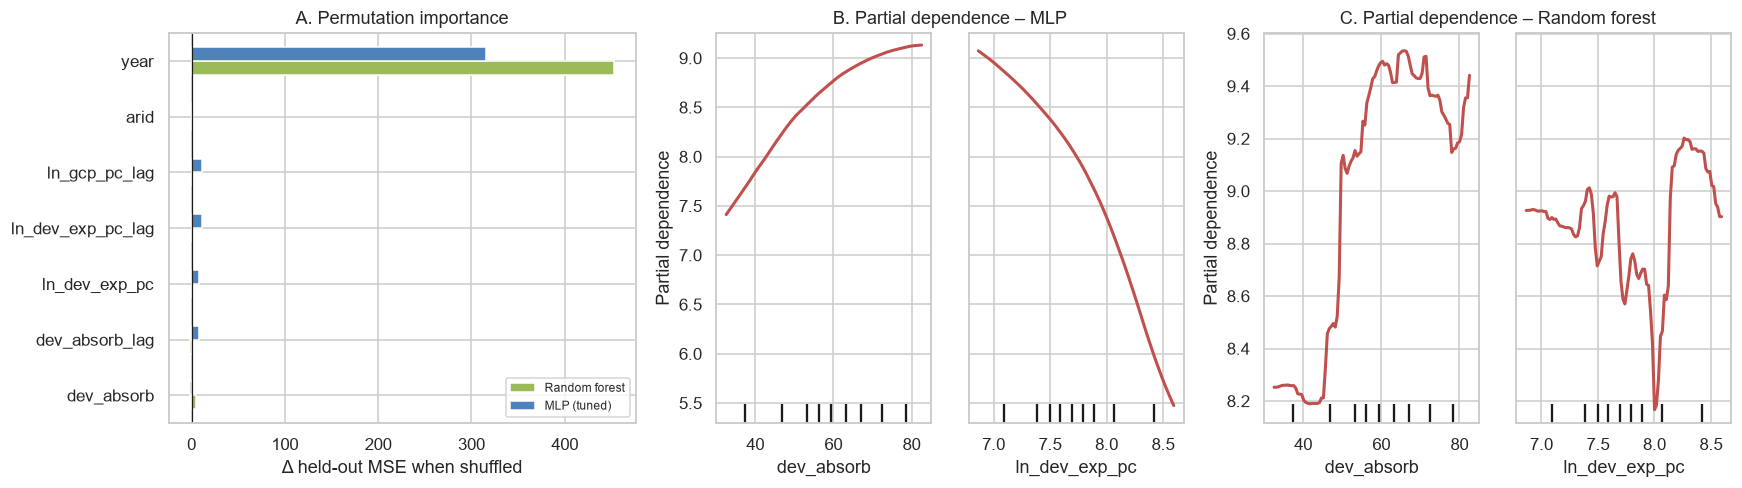

In [22]:
# ---- Permutation importance (out-of-sample, on held-out folds) and partial dependence for absorption ----
imp = {}
for name in ["Random forest", "MLP (tuned)"]:
    vals = []
    for tr, te in cv.split(X, y, groups):
        mdl = models[name].fit(X.iloc[tr], y.iloc[tr])
        r = permutation_importance(mdl, X.iloc[te], y.iloc[te], n_repeats=20, random_state=523, scoring="neg_mean_squared_error")
        vals.append(r.importances_mean)
    imp[name] = pd.Series(np.mean(vals, axis=0), index=feat_num + ["year"])
imp = pd.DataFrame(imp)
print("Permutation importance (increase in held-out MSE when the feature is shuffled; averaged over folds):")
display(imp.sort_values("MLP (tuned)", ascending=False).round(3))

mlp_full = models["MLP (tuned)"].fit(X, y)
rf_full = models["Random forest"].fit(X, y)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
ax = axes[0]
imp.plot.barh(ax=ax, color=["#9bbb59", "#4f81bd"]); ax.axvline(0, c="k", lw=.8)
ax.set_xlabel("Δ held-out MSE when shuffled"); ax.set_title("A. Permutation importance"); ax.legend(fontsize=8)
for ax, mdl, nm in zip(axes[1:], [mlp_full, rf_full], ["MLP", "Random forest"]):
    PartialDependenceDisplay.from_estimator(mdl, X, ["dev_absorb", "ln_dev_exp_pc"], ax=ax, kind="average",
                                            line_kw={"color": "#c0504d", "lw": 2})
    ax.set_title(f"B. Partial dependence – {nm}" if nm == "MLP" else f"C. Partial dependence – {nm}")
savefig("fig9_neural_network_benchmark")

**Interpretation.** Three results follow from the benchmark. First, a model that predicts every county's growth by the national mean for that year explains about 85 % of the variance in held-out counties; adding county fiscal and structural variables does not improve on this (linear 0.84, random forest 0.85), and the tuned MLP performs worse (0.79) — with roughly 300 observations and 47 clusters, additional flexibility is penalised rather than rewarded. Second, permutation importance attributes almost all predictive power to the year indicators; every other feature, including both absorption variables, changes held-out error by less than 4 % of the year effect, and several have negative (noise-level) importances. Third, the random-forest partial-dependence curve for absorption is flat below about 45 % and above about 55 %, with a step of roughly 1 pp of growth between them — a weak threshold pattern that is suggestive but, given its magnitude relative to the year effects and the in-sample nature of partial dependence, not something the data can establish; the MLP's steeper curves should be discounted given its inferior out-of-sample fit. Overall, allowing for arbitrary non-linearities and interactions does not reveal a relationship between absorption and growth that the linear fixed-effects models missed.

### 13. Findings and conclusion

#### Summary of findings and interpretation

| # | Question / hypothesis | Test & data | Key estimate | Finding | Interpretation |
|---|---|---|---|---|---|
| 1 | How much funding has reached counties? | COB national aggregates, 12 FYs | KES 4.36 tn released; releases exceeded spending in 12/12 years | Transfers have grown steadily | Counties have not been liquidity-constrained in aggregate |
| 2 | What share is spent on development? | Development share of county spending | 27 % overall; 35 % in FY14/15–15/16, 22–26 % since FY21/22 | Below the PFM Act's 30 % threshold and declining | Recurrent spending has grown faster than development spending; development spending has declined in real terms |
| H1 | Is development absorption persistently low without improvement? | National dev. vs recurrent absorption, FY13/14–24/25; per-county trends (§6.2) | Dev. 36–65 %, recurrent 83–93 %; median county trend +0.4 pp/yr; 4 counties improving, 3 deteriorating | **Supported** | No system-wide trend over twelve years; KES 867 bn of approved development budgets unspent |
| 3 | Is absorption a stable county characteristic? | Rank correlations, AR(1), variance decomposition | ρ = 0.16–0.56; AR(1) = 0.27; 40 % between / 60 % within | Predominantly year-to-year variation | Absorption appears to reflect transitory factors (cash-flow timing, procurement, elections) more than stable institutional differences |
| 4 | What is associated with absorption? | Two-way FE, §8.1 | −1 pp per 10 % larger dev. budget p.c. (p < 0.05); +33 pp per 10 pp own-source revenue share (p < 0.01, small sample) | Budget size and revenue composition | Part of the variation in absorption reflects the size of the approved budget; own-source revenue is associated with higher execution |
| H2 | Is absorption associated with GCP growth? | Pooled, two-way FE, lagged, extended panel; cluster bootstrap | Absorption: −0.25 pp per 10 pp (bootstrap 95 % CI −0.96 to +0.45); lagged dev. spending p.c.: +0.42 pp per 10 % (p < 0.01) | **Not supported** for the absorption rate; positive association for spending per capita | The level of development spending, with a one-year lag, is associated with growth; the share of budget executed is not |
| 5 | Can a non-linear model detect an absorption–growth relationship? | MLP, random forest vs ridge; county-grouped CV; permutation importance; partial dependence (§12.2) | CV R²: year-mean 0.85, linear 0.84, RF 0.85, MLP 0.79; absorption importance < 4 % of year effect | No | Flexible models do not outperform linear ones; year effects dominate; no robust threshold or interaction involving absorption |
| 6 | Did lower-income counties converge? | Between-county growth regression with arid indicator | Arid counties +1.9 pp/yr growth 2020–24 (p < 0.01); poverty +1.2 pp vs +3.7 pp elsewhere | Yes | The counties receiving the largest per-capita transfers recorded faster growth and smaller poverty increases |
| H3 | Is absorption associated with poverty change? | Long difference 2015/16→2022 with baseline controls | −1.8 pp poverty change per 10 pp decade-average absorption (p < 0.05); n.s. with 3-year window | **Weakly supported**, cumulative measure only | Consistent with execution mattering through the accumulated stock of completed assets; the effect is modest (≈5 pp between a 40 % and a 70 % absorber) |
| 7 | Is spending per capita associated with poverty change? | Same regression | +6.3 pp poverty change per log-point of dev. spending p.c. (p < 0.01) | Positive, likely confounded | The CRA formula directs more funding per capita to lower-income, shock-exposed counties (reverse causality); the estimate does not support a large poverty-reducing effect at current scale, nor does it establish a harmful one |
| H4 | Is absorption associated with project completion? | COB FY22/23 flagship projects, 46 counties | 30 % complete; completion share on absorption: R² ≈ 0.02, n.s. | **Not supported** | Settlement of prior-year pending bills counts towards absorption without adding to current completion; pending bills rose from KES 35 bn to 183 bn |
| 8 | Where is the unspent development budget concentrated? | Choropleths §8.2 | Nairobi City KES 36 bn, Nakuru KES 33 bn unspent; arid counties leave the smallest share unspent | Large urban counties | The national under-spend is concentrated in a small number of large urban counties |

#### Principal findings

**1. Transfers to counties have been substantial and have grown.** Across the twelve fiscal years since county governments were established (FY2013/14–FY2024/25) the National Treasury released approximately **KES 4.36 trillion** to the 47 counties, rising from KES 174 bn in the first year to KES 472 bn in FY2024/25. Exchequer releases exceeded total county spending in every year.

**2. A declining share has been spent on development.** Development spending accounted for between 22 % and 35 % of total county expenditure — 27 % over the whole period, compared with the 30 % threshold in the Public Finance Management Act — or approximately KES 1.16 trillion over twelve years. Relative to approved development budgets, counties executed 36 % in FY2013/14, 62–65 % in FY2014/15–2016/17, 48 % in the 2017 election year, and between 51 % and 62 % since, with no sustained trend. Recurrent budgets were executed at 83–93 %. In total, **KES 867 bn of approved development budgets were not spent** — equivalent to about seven years of development spending at the FY2024/25 level. H1 is supported.

**3. Absorption is predominantly a year-to-year rather than a county-level phenomenon.** About 40 % of the variation in county development absorption is between counties and 60 % is within-county variation across years. Rank correlations between consecutive years are 0.16–0.56 and the AR(1) coefficient is 0.27. Fitting a linear trend to each county's absorption since FY2013/14, four counties (Mandera, Meru, Nakuru, Makueni) show a statistically significant increase and three (Kisii, Bomet, Isiolo) a significant decrease; the median county trend is +0.4 pp a year. Over the six complete years, the highest average absorption is recorded in the arid north (Mandera 79 %, Marsabit 73 %, Wajir 71 %) and the lowest in the most urbanised counties (Nairobi City 40 %, Kisumu 41 %, Kisii 42 %, Nakuru 44 %). Within counties, a 10 % larger development budget per capita is associated with about 1 pp lower absorption, and a higher own-source-revenue share with higher absorption, patterns consistent with budget size and cash-flow timing being important determinants.

**4. The absorption rate is not associated with GCP growth or project completion.** In every specification — pooled, two-way fixed effects, lagged, the extended 2014–2025 panel, nominal or real growth, with or without Nairobi, the COVID year or the arid counties — the coefficient on the development absorption rate is small, varies in sign and is not statistically significant (H2). A 400-draw cluster bootstrap over counties gives a 95 % interval of −0.96 to +0.45 pp of growth per 10 pp of absorption. A tuned neural network and a random forest, evaluated on held-out counties, do not outperform a linear model or a year-mean benchmark, and attribute negligible predictive importance to absorption, so the null result is not attributable to functional-form restrictions. The absorption rate is likewise unrelated to the share of flagship projects completed (H4).

**5. Decade-average absorption is modestly associated with poverty change.** In the long-difference analysis (H3), conditional on baseline poverty, baseline income and spending per capita, a county whose development absorption averaged 10 pp higher over FY2013/14–2021/22 recorded a poverty increase about 1.8 pp smaller between 2015/16 and 2022 (p < 0.05; 1.5 pp, p < 0.10, excluding arid counties). The association is absent when absorption is measured over the three most recent years only, which is consistent with budget execution mattering through the cumulative stock of completed assets rather than through single-year performance. The magnitude is modest: the implied difference between a 40 % and a 70 % absorber is about 5 pp of poverty over six years.

**6. The level of development spending per capita is associated with subsequent growth.** Within counties, a 10 % increase in development spending per capita is followed by approximately 0.4 pp faster real GCP growth in the next year (p < 0.01 in the lagged two-way fixed-effects model; p < 0.10 in the lead-growth robustness checks). This is the only growth coefficient that is both statistically significant and consistently signed across specifications. Between counties, the eight arid counties, which receive the largest per-capita transfers under the CRA formula, grew about 1.9 pp a year faster than other counties in 2020–24 (p < 0.01) and recorded smaller poverty increases (+1.2 pp versus +3.7 pp), despite the 2021–23 drought.

**7. The poverty–spending association is positive and most plausibly reflects allocation rules.** Conditional on baseline poverty and income, counties with higher development spending per capita recorded larger poverty increases. The equitable-share formula directs more funding per person to small, lower-income, rural counties, which were also those most exposed to the drought, locust and food-price shocks of 2017–2022; this reverse-causality channel is the most plausible explanation. The estimate does not support a large poverty-reducing effect of county development spending at the scale observed, but given the identification problem it should not be read as evidence of a harmful effect. Nationally, mean county poverty rose from 40.6 % to 43.9 % and 14 of 47 counties recorded a decrease.

**8. Project completion is low and pending bills have grown.** Of 762 flagship development projects listed by COB for FY2022/23, 230 (30 %) were reported complete; the completion share is unrelated to absorption. County pending bills were KES 35–38 bn a year in 2015–2017, rose to KES 108 bn in FY2017/18, and reached KES 183 bn in FY2024/25 — approximately one and a half years of total county development spending.

#### Assessment

The evidence supports neither of the two positions that dominate public discussion of devolution in their simple forms.

The claim that devolution has not delivered development is not supported as stated: transfers have been made as constitutionally required for twelve consecutive years; the counties receiving the largest per-capita transfers have grown faster and recorded smaller poverty increases than others; and the level of development spending is associated with subsequent growth.

The claim that county performance can be read from the development absorption rate is also not supported. The absorption rate has no detectable association with county output growth or project completion, and only a modest association with poverty change when averaged over a decade. It measures expenditure relative to an approved budget whose size is itself a choice, and it can be raised by settling prior-year obligations without any new assets being completed. The analysis therefore suggests that conclusions about the success or failure of devolution that rest primarily on absorption rates — in either direction — are weakly founded.

The findings are consistent with a more specific characterisation: devolved transfers have redistributed resources towards historically under-served counties and are associated with measurable growth where spent; but the share of transfers allocated to development has declined, a large fraction of approved development budgets is not executed, pending bills have accumulated, and the indicator most commonly used to judge county performance is not closely related to development outcomes.

#### Implications

The following implications are suggested by the evidence; each would benefit from further study.

1. **Complementing absorption with output measures.** Reporting completed projects, unit costs and asset registers alongside absorption rates would give oversight bodies (COB, Senate, CRA) a measure more closely related to outcomes. The FY2022/23 COB project tables indicate that this is feasible with existing data.
2. **Monitoring the development share of expenditure.** Development spending has averaged 27 % of total expenditure and 22–26 % in recent years, below the 30 % threshold specified for budgets in the PFM Act. Monitoring realised rather than budgeted shares would better reflect actual resource use.
3. **Addressing pending bills.** The accumulation of KES 183 bn in pending bills is likely to affect both project completion and the interpretability of absorption rates; their settlement and prevention may be a precondition for improved delivery.
4. **Considering exchequer timing.** The low persistence of absorption and the positive association with own-source revenue are consistent with cash-flow timing affecting execution; the design of release schedules may be relevant to execution rates.
5. **Using multi-year measures.** Because absorption is associated with outcomes only when averaged over several years, performance assessments based on multi-year rolling execution and completion records are likely to be more informative than single-year rates.

#### Limitations

- County-level COB tables exist in consolidated form only for FY2019/20–FY2024/25. For FY2013/14–FY2018/19 county figures were extracted from narrative text in archived reports; only internally consistent rows (156 county-years) enter the spending variables, so early coverage is uneven across counties. The main fixed-effects panel is short (T = 5 for growth); the extended panel roughly doubles the sample but with missing cells.
- Absorption and spending are *reported* figures; COB itself notes inconsistencies in county returns. Values identified as parse errors in the revenue tables were dropped rather than corrected.
- Real GCP is an estimate constructed from national-accounts indicators rather than county production surveys, and the strong year effects in the growth data may partly reflect the estimation method; poverty is observed at only two points.
- The design is observational. Reverse causality (lower-income, slower-growing counties receive more per capita by formula) biases the spending coefficients towards zero or negative; the null result for absorption and growth is robust to every alternative tried, and the poverty result should be read as an association rather than a causal estimate.
- The machine-learning benchmark is limited by sample size (≈300 observations); its main value is in showing that flexible models do not recover a relationship the linear models missed, not in providing precise non-parametric estimates.
- Project data cover only each county's highest-expenditure projects in one year, as reported by COB.

### References

- Commission on Revenue Allocation. *County Allocation of Revenue Acts*, FY2013/14–FY2024/25. Nairobi: CRA.
- Kenya National Bureau of Statistics. *Gross County Product* 2019, 2021, 2023 and 2025 editions. Nairobi: KNBS.
- Kenya National Bureau of Statistics (2018). *Basic Report on Well-Being in Kenya, based on the 2015/16 KIHBS*. Nairobi: KNBS.
- Kenya National Bureau of Statistics (2024). *The Kenya Poverty Report 2022*. Nairobi: KNBS.
- Kenya National Bureau of Statistics (2019). *2019 Kenya Population and Housing Census, Volume I*. Nairobi: KNBS.
- Office of the Controller of Budget. *Annual County Governments Budget Implementation Review Reports*, FY2019/20–FY2024/25. Nairobi: OCOB.
- Republic of Kenya (2010). *The Constitution of Kenya*, Articles 202–203 and the Fourth Schedule.
- Runfola, D. et al. (2020). geoBoundaries: A global database of political administrative boundaries. *PLoS ONE* 15(4): e0231866. Kenya ADM1 layer (public domain).
- World Bank (2020). *Kenya Public Expenditure Review 2020: Options for Fiscal Consolidation after the COVID-19 Crisis*, Chapter on county governments.
- Full provenance for every data point: `data/sources.md` and `data/outcome_sources.md`.

### Reproducibility

- **Environment:** Python 3.14, pandas 3.0, statsmodels 0.15, linearmodels 7.1, scikit-learn 1.9, geopandas 1.1, seaborn, matplotlib. Run all cells top to bottom (`Kernel → Restart & Run All`); total run time ≈ 1–2 minutes, most of it in the 400-draw cluster bootstrap (§12.1) and the cross-validated model comparison (§12.2).
- **Inputs:** `data/county_fiscal_panel.csv`, `data/national_fiscal_aggregates.csv` (COB/CRA/Treasury), `data/county_gcp.csv`, `data/county_poverty.csv`, `data/county_population.csv` (KNBS), `data/county_projects.csv` (COB FY2022/23), `data/kenya_counties.geojson` (geoBoundaries). Source PDFs and extraction scripts are kept in `data/raw/`.
- **Outputs:** all figures are written to `county_absorption_figures/` (fig0 conceptual framework … fig9 neural-network benchmark, plus two map figures).
- **Random seed:** the bootstrap uses `np.random.default_rng(523)` and all scikit-learn models use `random_state=523`; results are exactly reproducible.
- **Data-quality rules applied in code:** transfers < KES 100 m and own-source revenue < KES 10 m treated as parse errors; pre-FY2019/20 county rows used only when expenditure ÷ budget reproduces the reported absorption rate within 3 pp; population interpolated between the 2009 and 2019 censuses and extrapolated at the inter-censal growth rate.

---

### Appendix A. Model summary table

All regression models estimated in the paper, in order of appearance. "Absorption" is the coefficient on the development absorption rate in the units used by that model (per 10 pp for the growth models, per 1 pp elsewhere); "Spending" is the coefficient on log development spending per capita (contemporaneous or lagged as indicated). Standard errors in parentheses; stars: * p < 0.10, ** p < 0.05, *** p < 0.01. The table is also written to `data/appendix_model_summary.csv`.

In [23]:
def _coef(res, names):
    # return 'coef (se)***' for the first of `names` present in a statsmodels or linearmodels result
    se_attr = "std_errors" if hasattr(res, "std_errors") else "bse"
    for nm in names:
        if nm in res.params.index:
            b, se, p = res.params[nm], getattr(res, se_attr)[nm], res.pvalues[nm]
            stars = "***" if p < .01 else "**" if p < .05 else "*" if p < .10 else ""
            return f"{b:.3f} ({se:.3f}){stars}"
    return "—"

def _r2(res):
    return getattr(res, "rsquared", np.nan)

A = ["absorb10", "absorb10_lag", "absorb", "absorb_2223"]
S = ["ln_dev_exp_pc", "ln_dev_exp_pc_lag", "ln_cum_dev_exp_pc"]
rows = []
EST = {"PanelEffectsResults": "PanelOLS (FE)", "PanelResults": "Pooled OLS", "RegressionResultsWrapper": "OLS"}
def add(section, model, res, dep, sample, fe, se_type, extra=""):
    rows.append({"Section": section, "Model": model, "Estimator": EST.get(type(res).__name__, type(res).__name__),
                 "Dependent variable": dep, "Sample": sample, "N": int(res.nobs), "Absorption": _coef(res, A), "Spending": _coef(res, S),
                 "Fixed effects": fe, "SEs": se_type, "R²": round(_r2(res), 3), "Notes": extra})

add("8.1", "(a) budget size", m_a, "Dev. absorption (%)", "47 counties, FY13/14–24/25 validated", "county + year", "clustered (county)", "ln dev. budget p.c.: " + _coef(m_a, ["ln_dev_budget_pc"]))
add("8.1", "(b) + revenue mix", m_b, "Dev. absorption (%)", "county-years with revenue tables", "county + year", "clustered (county)", "OSR share: " + _coef(m_b, ["osr_share"]))
for k, r in results.items():
    add("9", f"{k} {spec_key[k]}", r, "Real GCP growth (%)", "47 counties, 2020–24" if k != "(6)" else "extended 2014–25", "year" if k in ("(1)", "(2)") else "county + year", "clustered (county)")
add("9", "(B1) between-county", mb1, "Mean real GCP growth 2020–24", "47 counties (cross-section)", "none", "HC1")
add("9", "(B2) between-county + arid", mb2, "Mean real GCP growth 2020–24", "47 counties (cross-section)", "none", "HC1", "arid: " + _coef(mb2, ["arid"]))
for k, r in zip(["(1)", "(2)", "(3)", "(4) + arid", "(5) non-arid only"], [p1, p2, p3, p4, p5]):
    add("10", k, r, "Δ poverty 2015/16→2022 (pp)", "47 counties" if "non-arid" not in k else "39 non-arid counties", "none", "HC1", "baseline poverty: " + _coef(r, ["pov_2015"]))
for k, r in zip(["(1) 6-yr mean absorption", "(2) FY22/23 absorption", "(3) + spending, arid"], [q1, q2, q3]):
    add("11", k, r, "Flagship projects complete (%)", "46 counties, FY2022/23", "none", "HC1")
for k, r in rb.items():
    if k != "(4) base":
        add("12", f"robustness: {k}", r, "Real GCP growth (%)" if "lead" not in k else "Real GCP growth t+1 (%)", "47 counties" if "ext" not in k else "extended panel", "county + year", "clustered (county)")

appendix = pd.DataFrame(rows)
appendix.index = range(1, len(appendix) + 1); appendix.index.name = "#"
pd.set_option("display.max_colwidth", 60)
display(appendix)
appendix.to_csv(DATA / "appendix_model_summary.csv")

print("\nSupplementary estimates:")
print(f"  Cluster bootstrap (§12.1), baseline model (4): absorb10 95% CI [{boot.absorb10.quantile(.025):+.3f}, {boot.absorb10.quantile(.975):+.3f}], "
      f"bootstrap SE {boot.absorb10.std():.3f}; ln_dev_exp_pc 95% CI [{boot.ln_dev_exp_pc.quantile(.025):+.3f}, {boot.ln_dev_exp_pc.quantile(.975):+.3f}] (400 draws)")
print("  Machine-learning benchmark (§12.2), county-grouped 5-fold CV R²: " + ", ".join(f"{m} {v:.3f}" for m, v in scores["CV R²"].items()))
print(f"  AR(1) persistence of absorption (§8): coefficient {ar.params['dev_absorb_lag']:.3f} (SE {ar.bse['dev_absorb_lag']:.3f}), N = {int(ar.nobs)}")

,Section,Model,Estimator,Dependent variable,Sample,N,Absorption,Spending,Fixed effects,SEs,R²,Notes
#,,,,,,,,,,,,
1,8.1,(a) budget size,PanelOLS (FE),Dev. absorption (%),"47 counties, FY13/14–24/25 validated",438,—,—,county + year,clustered (county),0.02,ln dev. budget p.c.: -10.756 (5.015)**
2,8.1,(b) + revenue mix,PanelOLS (FE),Dev. absorption (%),county-years with revenue tables,125,—,—,county + year,clustered (county),0.14,OSR share: 334.691 (103.732)***
3,9,"(1) Pooled OLS, year FE",Pooled OLS,Real GCP growth (%),"47 counties, 2020–24",235,0.011 (0.147),—,year,clustered (county),0.19,
4,9,"(2) Pooled OLS + dev. spending p.c., year FE",Pooled OLS,Real GCP growth (%),"47 counties, 2020–24",235,-0.124 (0.213),0.697 (0.602),year,clustered (county),0.20,
5,9,(3) County + year FE,PanelOLS (FE),Real GCP growth (%),"47 counties, 2020–24",235,0.029 (0.210),—,county + year,clustered (county),0.00,
6,9,(4) County + year FE + dev. spending p.c.,PanelOLS (FE),Real GCP growth (%),"47 counties, 2020–24",235,-0.248 (0.432),1.492 (1.974),county + year,clustered (county),0.00,
7,9,"(5) County + year FE, regressors lagged one FY",PanelOLS (FE),Real GCP growth (%),"47 counties, 2020–24",218,-0.364 (0.378),4.248 (1.610)***,county + year,clustered (county),0.04,
8,9,"(6) As (4), extended panel 2014–2025 (validated early rows)",PanelOLS (FE),Real GCP growth (%),extended 2014–25,391,0.569 (0.427),-2.095 (1.997),county + year,clustered (county),0.01,
9,9,(B1) between-county,OLS,Mean real GCP growth 2020–24,47 counties (cross-section),47,-0.021 (0.022),0.253 (0.639),none,HC1,0.09,



Supplementary estimates:
  Cluster bootstrap (§12.1), baseline model (4): absorb10 95% CI [-0.956, +0.454], bootstrap SE 0.376; ln_dev_exp_pc 95% CI [-1.776, +4.803] (400 draws)
  Machine-learning benchmark (§12.2), county-grouped 5-fold CV R²: Linear (ridge) 0.839, Random forest 0.851, MLP (tuned) 0.789, Year-mean only (benchmark) 0.846
  AR(1) persistence of absorption (§8): coefficient 0.266 (SE 0.049), N = 479


### Appendix B. Variable definitions

| Variable | Definition | Source |
|---|---|---|
| `dev_absorb` | Development expenditure ÷ approved development budget × 100, by county and fiscal year | COB CBIRR |
| `absorb10` | `dev_absorb` ÷ 10 (coefficient = effect of a 10 pp change) | derived |
| `development_expenditure_kes`, `development_budget_kes` | Development spending and approved development budget, KES | COB CBIRR |
| `dev_exp_pc`, `ln_dev_exp_pc` | Development expenditure per capita (KES) and its natural log; population interpolated/extrapolated from the 2009 and 2019 censuses | COB, KNBS |
| `equitable_share_allocation_kes`, `total_exchequer_disbursed_kes` | Equitable share allocated (CARA) and actually released to the county | CRA, COB, Treasury |
| `own_source_revenue_kes`, `osr_share` | Own-source revenue collected; OSR ÷ (OSR + equitable share) | COB |
| `g_real`, `g_nominal` | 100 × Δ ln real (nominal) Gross County Product, calendar year | KNBS GCP |
| `g_real_lead` | `g_real` in the following calendar year | derived |
| `gcp_per_capita_kes` | Nominal GCP per capita | KNBS GCP |
| `pov_2015`, `pov_2022`, `d_pov` | Overall poverty headcount (%) in KIHBS 2015/16 and KCHS 2022; difference in pp | KNBS |
| `projects_total`, `projects_completed`, `completed_share` | Flagship development projects listed per county and those reported 100 % complete, FY2022/23 | COB |
| `arid`, `asal` | Indicator for the 8 arid counties / the 23 arid and semi-arid counties (NDMA classification) | NDMA |
| `validated` | Early-year (FY2013/14–2018/19) county row passes the internal-consistency check (expenditure ÷ budget within 3 pp of reported absorption) | derived |
| `year` | Calendar year in which the fiscal year ends (FY2019/20 → 2020) | derived |